In [1]:
import os
import sys

# Get the absolute path of the directory containing the notebook (notebooks/)
current_dir = os.path.abspath('')

# Add the parent directory (SingleWordProductionDutch/) to the system path
# This allows Python to find 'src'
parent_dir = os.path.dirname(current_dir)
sys.path.append(parent_dir)

import numpy as np
import scipy.signal
from scipy.signal import hilbert
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import pearsonr
from pynwb import NWBHDF5IO
from sklearn.metrics import mean_squared_error
from scipy.stats import mannwhitneyu
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests


import pandas as pd
import numpy.matlib as matlib
import scipy.signal
from notebookfunctions import *
import matplotlib.pyplot as plt
from IPython.display import display, clear_output 

feat_path = r'./features'
result_path = r'./results'


winL = 0.05
frameshift = 0.01
modelOrder = 4
stepSize = 5
sr=1024
path_bids = '/Users/lisa/Documents/DSAI_year2/Marble/SingleWordProductionDutch/SingleWordProductionDutch-iBIDS'
path_somata = '/Users/lisa/Documents/DSAI_year2/SingleWordProductionDutch-1/somata'

pts = ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10']


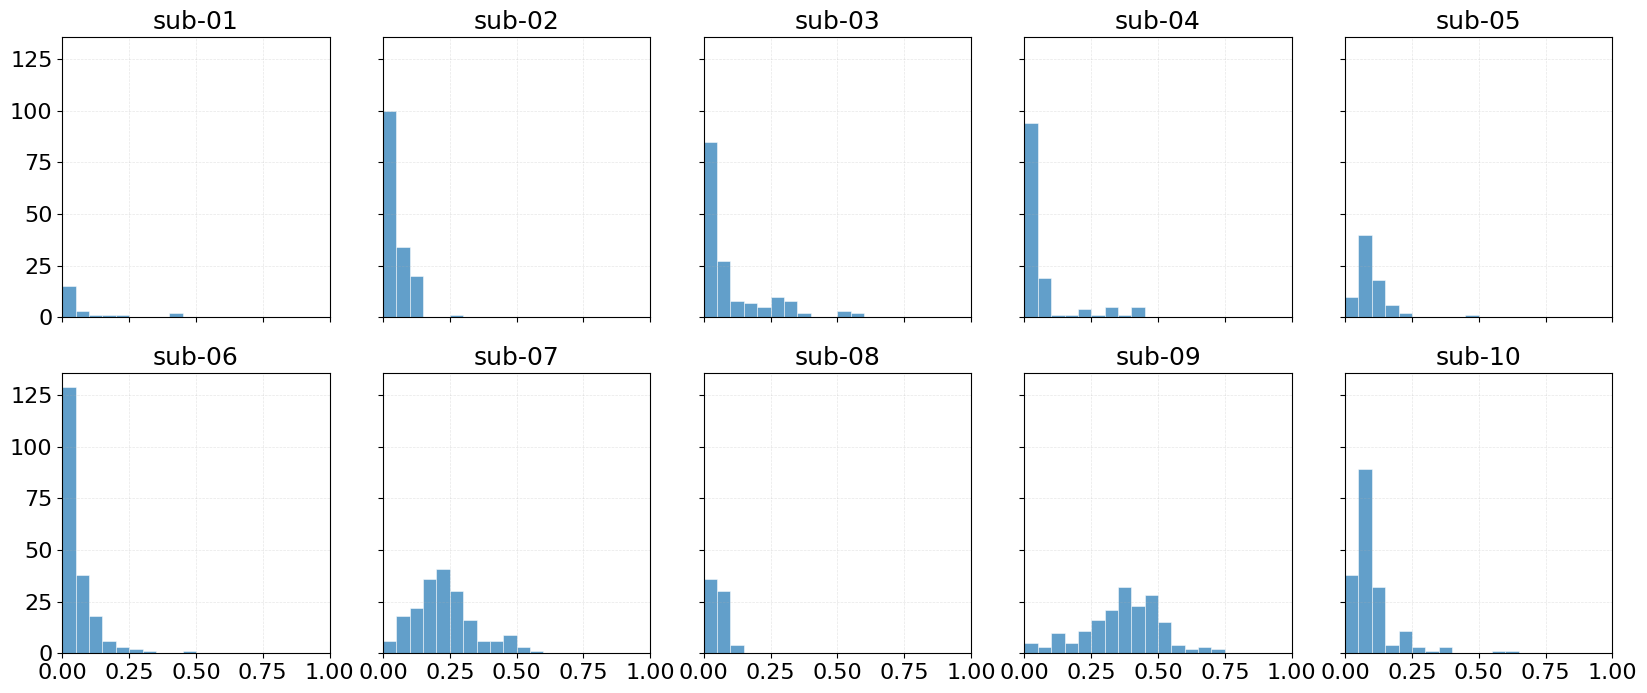

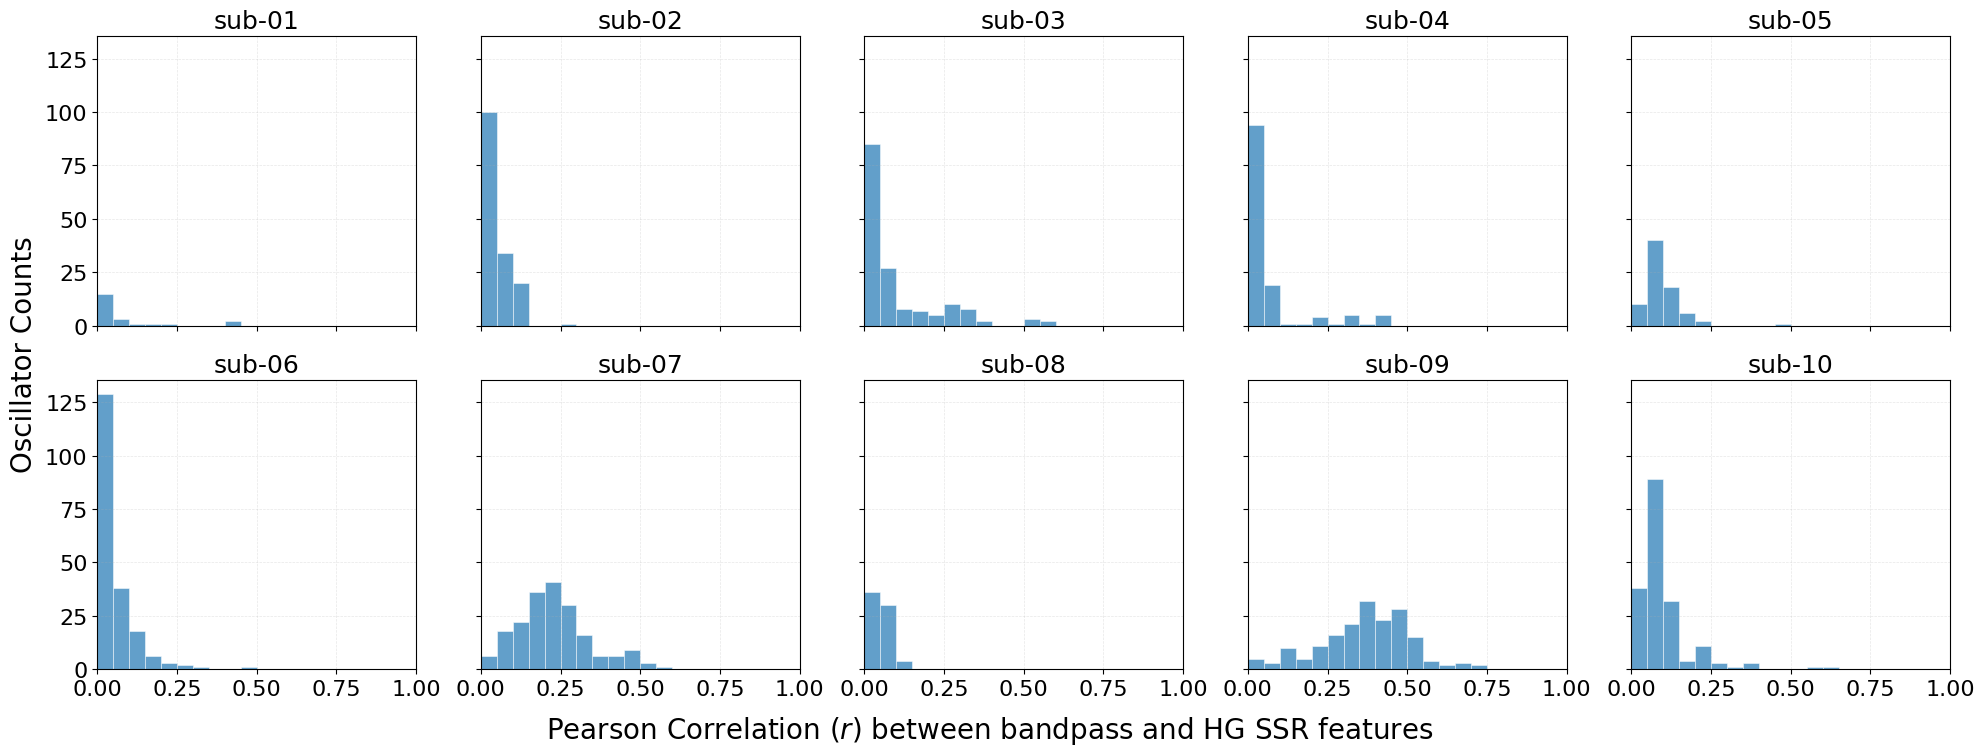

all pr: mean: 0.100, median: 0.048, %above 0.7: 0.1%
['pt: sub-01, mean: -0.037, median: -0.047, %above 0.7: 0.0%', 'pt: sub-02, mean: 0.033, median: 0.027, %above 0.7: 0.0%', 'pt: sub-03, mean: 0.073, median: 0.030, %above 0.7: 0.0%', 'pt: sub-04, mean: 0.046, median: 0.010, %above 0.7: 0.0%', 'pt: sub-05, mean: 0.083, median: 0.078, %above 0.7: 0.0%', 'pt: sub-06, mean: 0.042, median: 0.025, %above 0.7: 0.0%', 'pt: sub-07, mean: 0.230, median: 0.219, %above 0.7: 0.0%', 'pt: sub-08, mean: 0.045, median: 0.048, %above 0.7: 0.0%', 'pt: sub-09, mean: 0.364, median: 0.382, %above 0.7: 1.1%', 'pt: sub-10, mean: 0.096, median: 0.075, %above 0.7: 0.0%']


In [3]:
#plots histograms of  correlation between bandpass features and amplitude features of hg ssr oscillators
%matplotlib inline

fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

hilbert3 = lambda x: scipy.signal.hilbert(x, scipy.fftpack.next_fast_len(len(x)), axis=0)[:len(x)]

plot_color = 'C0'

prints = []
all_r =[]
for i, pt in enumerate(pts):
    ax = axes[i]
    
    # Load feature arrays
    hga = np.load(os.path.join(feat_path, f'{pt}_final_bandpass_hg.npy'))
    sspe = np.load(os.path.join(feat_path, f'{pt}_onlyAMP_SSPEfeat.npy'))
    initParams_list = get_initParams(pt)
    num_channels = len(initParams_list)
    
    # Load Raw iEEG Data for reference
    nwb_path = os.path.join(path_bids, pt, 'ieeg', f'{pt}_task-wordProduction_ieeg.nwb')
    with NWBHDF5IO(nwb_path, 'r') as io:
        nwbfile = io.read()
        data = nwbfile.acquisition['iEEG'].data[:]
        
    data_amp = np.abs(hilbert3(data))
    numWindows = int(np.floor((data.shape[0] - winL * sr) / (frameshift * sr)))
    raw_envelopes = np.zeros((numWindows, data.shape[1]))
    
    for win in range(numWindows):
        start = int(np.floor((win * frameshift) * sr))
        stop = int(np.floor(start + winL * sr))
        raw_envelopes[win, :] = np.mean(data_amp[start:stop, :], axis=0)
        

    # Compute Correlation for each High-Gamma oscillator
    r_values = []
    start_col = 0
    for ch_idx in range(num_channels):
        freqs = np.array(initParams_list[ch_idx]['freqs'])
        current_n_osc = len(freqs)
        

        feat_hga = hga[:, ch_idx]
        
        individual_oscs = sspe[:, start_col : start_col + current_n_osc]
        start_col += current_n_osc # slide the counter for the next channel
        
        # Find all oscillators on this channel between 70 and 170 Hz
        hg_mask = (freqs >= 70) & (freqs <= 170)
        hg_indices = np.where(hg_mask)[0]
        
        for osc_idx in hg_indices:
            feat_sspe_hg = individual_oscs[:, osc_idx]
            min_len = min(len(feat_hga), len(feat_sspe_hg))
            
            # Calculate r for this oscillator
            if np.std(feat_hga[:min_len]) > 0 and np.std(feat_sspe_hg[:min_len]) > 0:
                r_matrix = np.corrcoef(feat_hga[:min_len], feat_sspe_hg[:min_len])
                r_values.append(r_matrix[0, 1])  # Append this oscillator's r
                all_r.append(r_matrix[0, 1])


    r_values = np.array(r_values)

    #Metrics:
    # percentage of oscillators with a correlation above 0.7
    pct_above_07 = (np.sum(r_values > 0.7) / len(r_values)) * 100 if len(r_values) > 0 else 0
    
    print(f"pt: {pt}, mean: {np.mean(r_values):.3f}, median: {np.median(r_values):.3f}, %above 0.7: {pct_above_07:.1f}%")
    prints.append (f"pt: {pt}, mean: {np.mean(r_values):.3f}, median: {np.median(r_values):.3f}, %above 0.7: {pct_above_07:.1f}%")
    
    # Plot histograms
    bins = np.arange(0, 1, 0.05)
    ax.hist(r_values, bins=bins, color=plot_color, alpha=0.7, edgecolor='white', linewidth=0.5)
    
    ax.set_title(pt, fontsize=18)
    ax.set_xlim([0, 1.0])
    ax.grid(True, which='major', linestyle='--', linewidth=0.5, alpha=0.3)
    ax.tick_params(axis='both', labelsize=16)

    clear_output(wait=True)
    display(fig)

# Global labels
fig.text(0.5, 0.02, 'Pearson Correlation ($r$) between bandpass and HG SSR features', ha='center', fontsize=20)
fig.text(0.01, 0.5, 'Oscillator Counts', va='center', rotation='vertical', fontsize=20)

plt.tight_layout(rect=[0.02, 0.05, 1, 0.95])
plt.savefig(os.path.join(result_path, 'SSR_bandpass_correlation_grid.png'), dpi=300)
plt.show()



r_values = np.array(all_r)

pct_above_07 = (np.sum(r_values > 0.7) / len(r_values)) * 100 if len(r_values) > 0 else 0

# Print the clean metrics dashboard
print(f"all pr: mean: {np.mean(r_values):.3f}, median: {np.median(r_values):.3f}, %above 0.7: {pct_above_07:.1f}%")

print(prints)

In [6]:
duration_sec = 5 #time we want to display
t_start = 10 #start time
feat_sr = 1 / 0.01  # since frameshift is 0.01

start_win = int(t_start * feat_sr)
num_wins = int(duration_sec * feat_sr) 
end_win = start_win + num_wins
t = np.linspace(t_start, t_start + duration_sec, num_wins)


def get_feat_for_plt(pt, ch_idx):
    hga = np.load(os.path.join(feat_path,f'{pt}_final_bandpass_hg.npy'))
    sspe = np.load(os.path.join(feat_path,f'{pt}_onlyAMP_SSPEfeat.npy'))

    #print(f'hga.shape: {hga.shape}, sspe.shape: {sspe.shape}')
    
    
    feat_hga = hga[start_win : end_win, ch_idx].flatten()
    feat_hga_norm = (feat_hga - np.mean(feat_hga)) / np.std(feat_hga) # Normalize for visual comparison so they sit on top of each other
    
    initParams_list = get_initParams(pt)
    initParams = initParams_list[ch_idx]
    freqs = initParams_list[ch_idx]['freqs']

    start_col = 0
    for i in range(ch_idx):
        start_col += len(initParams_list[i]['freqs'])
    
    # The number of oscillators for the current channel
    current_n_osc = len(freqs)

    # Get the individual oscillator columns for this channel
    individual_oscs = sspe[start_win : end_win, start_col : start_col + current_n_osc]
    
    # Sum them for the total SSPE feature
    feat_sspe = np.sum(individual_oscs, axis=1)
    
    if np.std(feat_sspe) ==0:
        print(f"std sspe: {np.std(feat_sspe)}, ch_idx: {ch_idx}")
        print('feat sspe ',feat_sspe)
        feat_sspe_norm = feat_sspe
    feat_sspe_norm = (feat_sspe - np.mean(feat_sspe)) / np.std(feat_sspe)

    
    # Normalize individual oscillators for comparison
    # return these as a list of normalized arrays
    indiv_oscs_norm = []
    for i in range(current_n_osc):
        osc = individual_oscs[:, i]
        if np.std(osc) > 0:
            indiv_oscs_norm.append((osc - np.mean(osc)) / np.std(osc))
        else:
            indiv_oscs_norm.append(osc) # handle zero-variance case
    
    #raw data features
    winL = 0.05
    frameshift = 0.01
    modelOrder = 4
    stepSize = 5
    path_bids = '/Users/lisa/Documents/DSAI_year2/Marble/SingleWordProductionDutch/SingleWordProductionDutch-iBIDS'
    io = NWBHDF5IO(os.path.join(path_bids,pt,'ieeg',f'{pt}_task-wordProduction_ieeg.nwb'), 'r')
    nwbfile = io.read()
    data = nwbfile.acquisition['iEEG'].data[:]
    io.close()
    
    #Small helper function to speed up the hilbert transform by extending the length of data to the next power of 2
    hilbert3 = lambda x: scipy.signal.hilbert(x, scipy.fftpack.next_fast_len(len(x)),axis=0)[:len(x)]
    
    numWindows = int(np.floor((data.shape[0]-winL*sr)/(frameshift*sr)))
 
    #Create feature space
    data = np.abs(hilbert3(data))
    feat = np.zeros((numWindows,data.shape[1]))
    for win in range(numWindows):
        start= int(np.floor((win*frameshift)*sr))
        stop = int(np.floor(start+winL*sr))
        feat[win,:] = np.mean(data[start:stop,:],axis=0)
    
    raw_envelope = feat[start_win : end_win, ch_idx]
    
    # Normalize for visual comparison so they sit on top of each other
    raw_envelope_norm = (raw_envelope - np.mean(raw_envelope)) / np.std(raw_envelope)

    
    return raw_envelope_norm, feat_hga_norm, feat_sspe_norm, np.array(indiv_oscs_norm), freqs

no hg in 7 channels
channel 0 for participant sub-07:
fit hga to raw envelope
Correlation (r): 0.0334
RMSE:            1.3904
R-squared:       -0.9332

fit sspe to raw envelope
Correlation (r): 0.6023
RMSE:            0.8919
R-squared:       0.2046

SSPE vs HGA features correlation: 0.0090


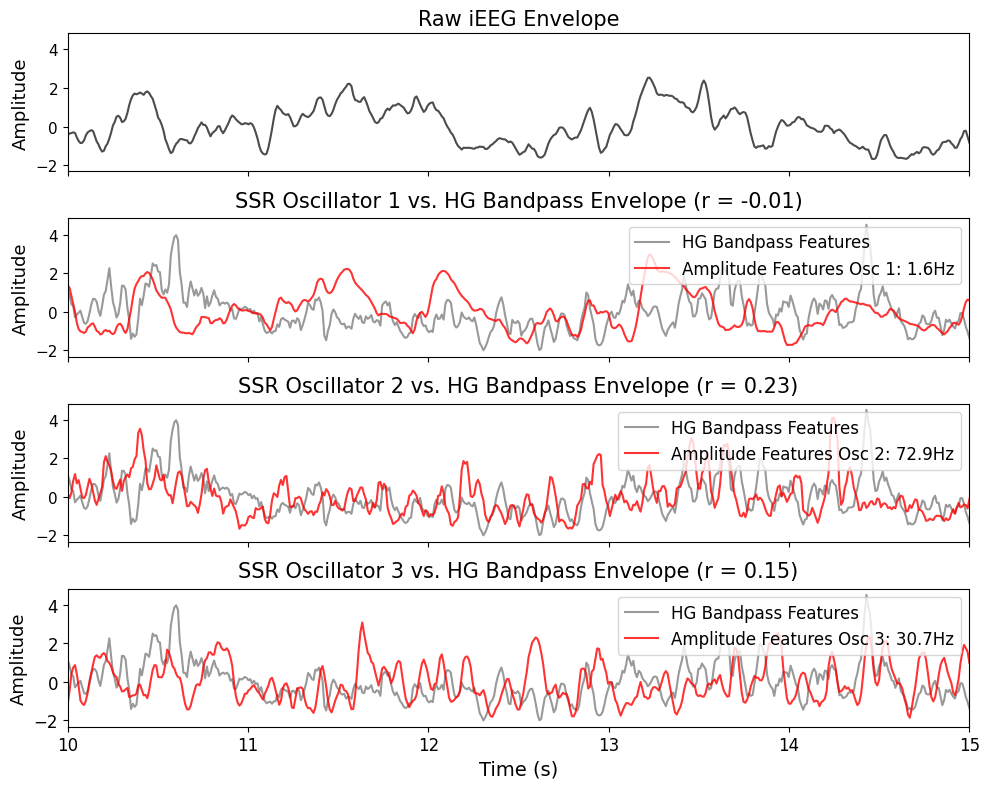

In [7]:
#plots amplitude SSR features and compares to bandpass features and raw data envelope



pt = 'sub-07'

for ch_idx in range(1):
    raw_envelope_norm, feat_hga_norm, feat_sspe_norm, indiv_oscs_norm, freqs = get_feat_for_plt(pt, ch_idx)
    print(f'channel {ch_idx} for participant {pt}:')
    
    # Correlation measures the linear relationship (timing/envelope similarity)
    corr, _ = pearsonr(feat_hga_norm, raw_envelope_norm)
    # RMSE measures the absolute difference (fit quality)
    rmse = np.sqrt(mean_squared_error(feat_hga_norm, raw_envelope_norm))
    #R-squared
    ss_res = np.sum((raw_envelope_norm - feat_hga_norm) ** 2)
    ss_tot = np.sum((raw_envelope_norm - np.mean(raw_envelope_norm)) ** 2)
    r_sq = 1 - (ss_res / ss_tot)

    print("fit hga to raw envelope")
    print(f'Correlation (r): {corr:.4f}')
    print(f'RMSE:            {rmse:.4f}')
    print(f'R-squared:       {r_sq:.4f}\n')
    
    # now for hga vs raw
    corr, _ = pearsonr(raw_envelope_norm, feat_sspe_norm)
    # RMSE measures the absolute difference (fit quality)
    rmse = np.sqrt(mean_squared_error(raw_envelope_norm, feat_sspe_norm))
    #R-squared
    ss_res = np.sum((raw_envelope_norm - feat_sspe_norm) ** 2)
    ss_tot = np.sum((raw_envelope_norm - np.mean(raw_envelope_norm)) ** 2)
    r_sq = 1 - (ss_res / ss_tot)

    print("fit sspe to raw envelope")
    print(f'Correlation (r): {corr:.4f}')
    print(f'RMSE:            {rmse:.4f}')
    print(f'R-squared:       {r_sq:.4f}\n')

    # Correlation between standard Hilbert HGA and your SSPE version
    r_val, _ = pearsonr(feat_hga_norm, feat_sspe_norm)
    print(f"SSPE vs HGA features correlation: {r_val:.4f}")
    
    
    fig, axes = plt.subplots(1 + len(freqs), 1, figsize=(10, 8), sharex=True, sharey=True)
    plt.rc('legend', fontsize=12)
    
    # Top: Raw iEEG Feature (Broadband baseline)
    axes[0].plot(t, raw_envelope_norm, color='black', alpha=0.7)
    axes[0].set_title(f'Raw iEEG Envelope', fontsize=15)
    axes[0].set_ylabel('Amplitude', fontsize=13)
    axes[0].tick_params(axis='both', labelsize=11)

    # plot individual oscillators
    for i in range(len(freqs)):
        ax_idx = 1 + i
        axes[ax_idx].plot(t, feat_hga_norm, color='black', alpha=0.4, label='HG Bandpass Features')
        #print(np.array(indiv_oscs_norm).shape)
        axes[ax_idx].plot(t, indiv_oscs_norm[i,:], color='red', alpha=0.8, label=f'Amplitude Features Osc {i+1}: {freqs[i]:.1f}Hz')
        #axes[ax_idx].plot(t, indiv_oscs_norm[i]+1, color='red', alpha=0.8, label=f'phase sin Osc {i+1}: {freqs[i]:.1f}Hz')
        #axes[ax_idx].plot(t, indiv_oscs_norm[i]+2, color='red', alpha=0.8, label=f'phase cos Osc {i+1}: {freqs[i]:.1f}Hz')
        #axes[ax_idx].plot(t, indiv_oscs_norm[i]+3, color='red', alpha=0.8, label=f'pac Osc {i+1}: {freqs[i]:.1f}Hz')
        
        # Calculate correlation for this specific frequency
        r, _ = pearsonr(feat_hga_norm, indiv_oscs_norm[i,:])
        axes[ax_idx].set_title(f"SSR Oscillator {i+1} vs. HG Bandpass Envelope (r = {r:.2f})", fontsize=15, pad=8)
        axes[ax_idx].set_ylabel('Amplitude', fontsize=13)
        axes[ax_idx].tick_params(axis='both', labelsize=11)
        axes[ax_idx].legend(loc='upper right')


    
    # Explicitly force the x-limits on the shared axis
    axes[-1].set_xlim(10, 15)
    axes[-1].set_xlabel('Time (s)', fontsize=14)
    axes[-1].tick_params(axis='both', labelsize=12)
    
    plt.tight_layout()
    plt.savefig(os.path.join(result_path, 'osc_viz.png'), dpi=600)
    plt.show()

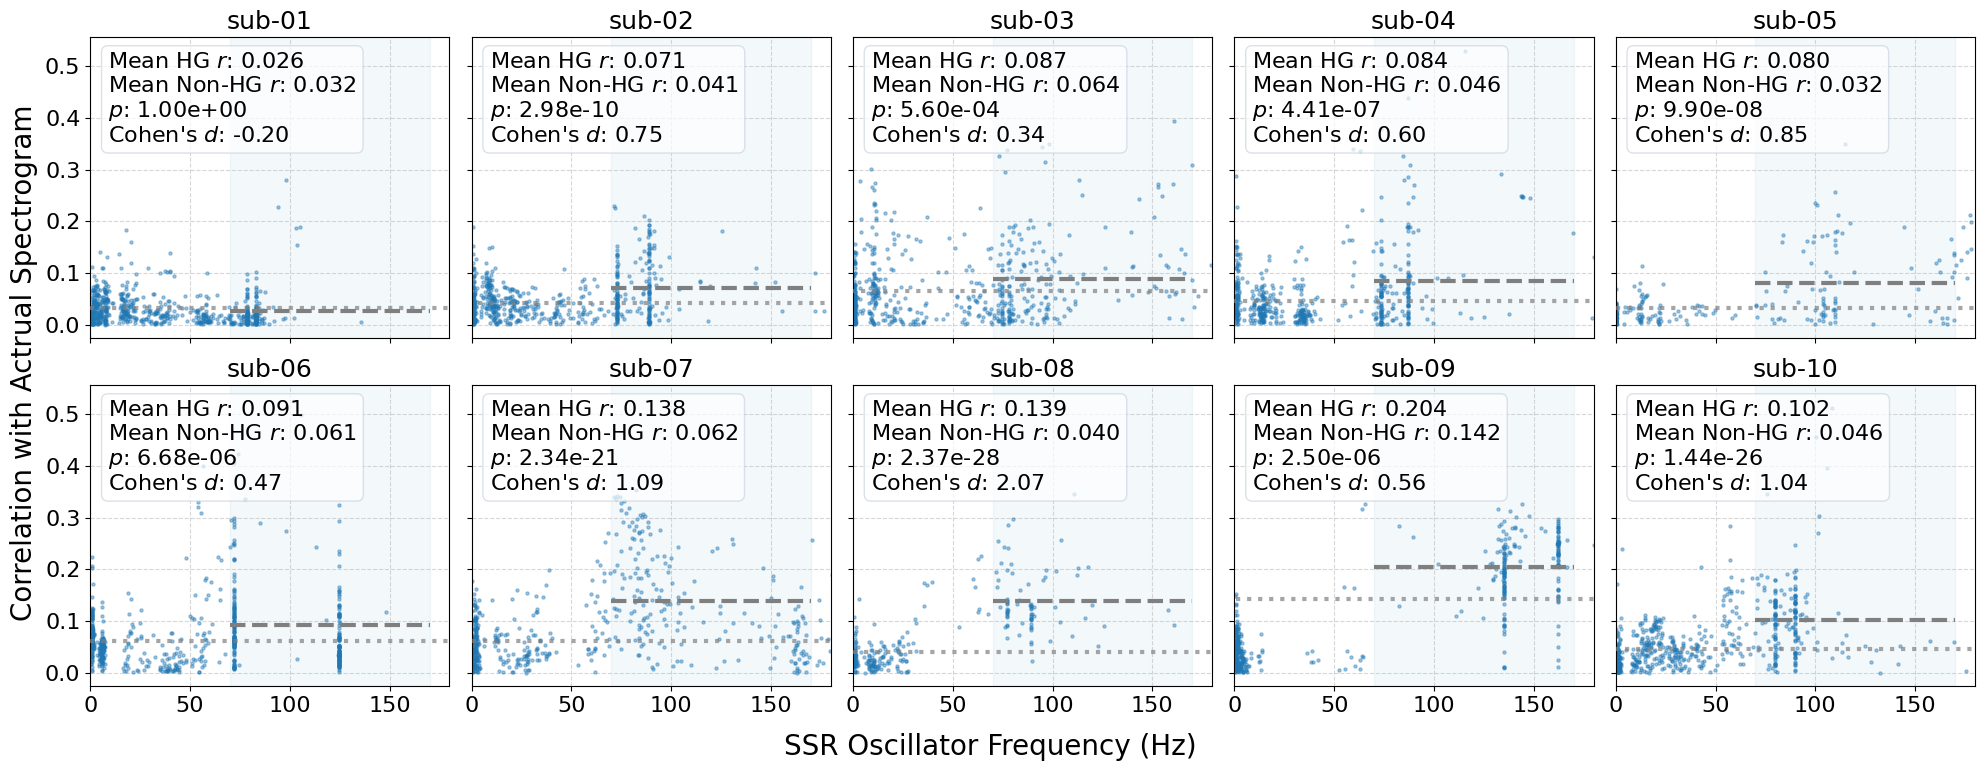

In [14]:

#plots correlation of amplitude ssr features and correlation to the ground-truth audio spectrogram
%matplotlib inline


# Helper function to calculate Cohen's d effect size
def cohen_d(x, y):
    nx, ny = len(x), len(y)
    if nx == 0 or ny == 0:
        return 0
    dof = nx + ny - 2
    pooled_std = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / dof)
    if pooled_std == 0:
        return 0
    return (np.mean(x) - np.mean(y)) / pooled_std

pts = ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10']


fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

for i, pt in enumerate(pts):
    ax = axes[i]
    
    sspe = np.load(os.path.join(feat_path, f'{pt}_onlyAMP_SSPEfeat.npy'))
    initParams_list = get_initParams(pt)
    
    spectrogram = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
    audio_env = np.mean(spectrogram, axis=1)
    audio_env = (audio_env - np.mean(audio_env)) / np.std(audio_env)
    
    all_freqs = []
    all_corrs = []    
    
    # Loop through every channel
    start_col = 0
    for ch_idx in range(len(initParams_list)):
        freqs = initParams_list[ch_idx]['freqs']
        n_osc = len(freqs)
        
        # Calculate correlation for every oscillator in this channel
        for j in range(n_osc):
            osc_data = sspe[:len(audio_env), start_col + j]
            osc_data = (osc_data - np.mean(osc_data)) / np.std(osc_data)
            
            r = np.corrcoef(osc_data, audio_env)[0, 1]
            
            all_freqs.append(freqs[j])
            all_corrs.append(abs(r)) 
            
        start_col += n_osc
        
    all_freqs = np.array(all_freqs)
    all_corrs = np.array(all_corrs)

    #numeric calculations
    hg_mask = (all_freqs >= 70) & (all_freqs <= 170)
    hg_corrs = all_corrs[hg_mask]
    non_hg_corrs = all_corrs[~hg_mask]
    
    mean_hg = np.mean(hg_corrs) if len(hg_corrs) > 0 else 0
    mean_non_hg = np.mean(non_hg_corrs) if len(non_hg_corrs) > 0 else 0

    d_val = cohen_d(hg_corrs, non_hg_corrs)
    
    if len(hg_corrs) > 0 and len(non_hg_corrs) > 0:
        stat, p_val = mannwhitneyu(hg_corrs, non_hg_corrs, alternative='greater')
    else:
        p_val = 1.0
    
    # Plotting
    
    # background HG area shading
    ax.axvspan(70, 170, color='C0', alpha=0.05, zorder=1)
    
    # Scatter points
    ax.scatter(all_freqs, all_corrs, alpha=0.4, s=5, color='C0', zorder=2)
    
    # group mean horizontal line indicators
    if len(hg_corrs) > 0:
        ax.hlines(mean_hg, 70, 170, colors='C7', linestyles='--', linewidth=3, zorder=3)
    ax.hlines(mean_non_hg, min(all_freqs), max(all_freqs), alpha=0.7, colors='C7', linestyles=':', linewidth=3, zorder=3)
    
    # Overlay the statistics values inside the subplot
    stats_text = (f"Mean HG $r$: {mean_hg:.3f}\n"
                  f"Mean Non-HG $r$: {mean_non_hg:.3f}\n"
                  f"$p$: {p_val:.2e}\n"#p_val:.3f}")
                  f"Cohen's $d$: {d_val:.2f}")
    
    props = dict(boxstyle='round',pad=0.3, facecolor='#ffffff', edgecolor='#cbd5e1', alpha=0.7)
    ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=16,
            verticalalignment='top', bbox=props)
    
    # Subplot Borders and Labels
    ax.set_title(pt, fontsize=18)
    ax.set_xlim([0, 180])
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.tick_params(axis='both', labelsize=16)

# Global labels
fig.text(0.5, 0.01, 'SSR Oscillator Frequency (Hz)', ha='center', fontsize=20)
fig.text(0.01, 0.5, 'Correlation with Actrual Spectrogram', va='center', rotation='vertical', fontsize=20)

plt.tight_layout(rect=[0.02, 0.04, 1, 0.96])

plt.savefig(os.path.join(result_path, 'Feature_Audio_Correlations_All_Subjects.png'), dpi=300)
plt.show()

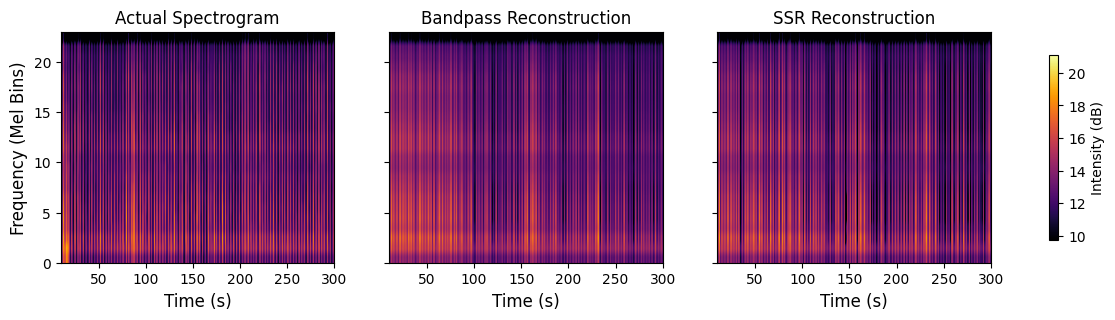

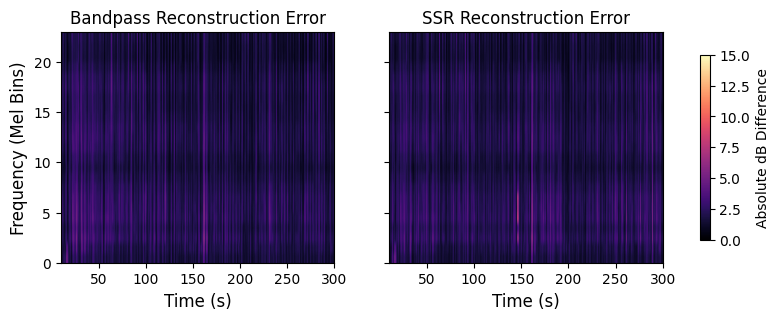

In [15]:
##spectrograms and error maps (old version)


pt = 'sub-01'
title_size = 12
ax_size = 12
figsize = (15, 3)
max_error_visible = 15
extent_vals = [10, 300, 0, 23]


spec1_full = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
spec2 = np.load(os.path.join(result_path, f'{pt}_bandpass_predicted_spec.npy'))
spec3 = np.load(os.path.join(result_path, f'{pt}_PAC_predicted_spec.npy'))

spec1 = spec1_full[1000:, :]

def to_db(x):
    return 20 * np.log10(np.maximum(x, 1e-5))

db_actual   = to_db(spec1).T 
db_bandpass = to_db(spec2).T 
db_ssr      = to_db(spec3).T 

error_bandpass = np.abs(db_actual - db_bandpass)
error_ssr      = np.abs(db_actual - db_ssr)


# plot spectrograms
fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)
plots = [db_actual, db_bandpass, db_ssr]
titles = ["Actual Spectrogram", "Bandpass Reconstruction", "SSR Reconstruction"]

vmin = np.percentile(db_actual, 5)   
vmax = np.percentile(db_actual, 99)  

for i, ax in enumerate(axes):
    im = ax.imshow(plots[i], aspect='auto', origin='lower', cmap='inferno', vmin=vmin, vmax=vmax, extent=extent_vals)
    ax.set_title(titles[i], fontsize=title_size)
    ax.set_xlabel("Time (s)", fontsize=ax_size)
    if i == 0:
        ax.set_ylabel("Frequency (Mel Bins)", fontsize=ax_size)

# Your preferred automatic colorbar method
fig.colorbar(im, ax=axes.ravel().tolist(), label="Intensity (dB)", shrink=0.8)

plt.savefig(os.path.join(result_path, 'spectograms.png'), dpi=300, bbox_inches='tight')
plt.show()



# Error Maps
fig, axes = plt.subplots(1, 3, figsize=figsize, sharey=True)

# Plot Bandpass Error
im = axes[0].imshow(error_bandpass, aspect='auto', origin='lower', cmap='magma', vmin=0, vmax=max_error_visible, extent=extent_vals)
axes[0].set_title("Bandpass Reconstruction Error", fontsize=title_size)
axes[0].set_ylabel("Frequency (Mel Bins)", fontsize=ax_size)
axes[0].set_xlabel("Time (s)", fontsize=ax_size)

# Plot SSR Error
im = axes[1].imshow(error_ssr, aspect='auto', origin='lower', cmap='magma', vmin=0, vmax=max_error_visible, extent=extent_vals)
axes[1].set_title("SSR Reconstruction Error", fontsize=title_size)
axes[1].set_xlabel("Time (s)", fontsize=ax_size)

fig.delaxes(axes[2])
fig.colorbar(im, ax=axes[:2].tolist(), label="Absolute dB Difference", shrink=0.8)

plt.savefig(os.path.join(result_path, 'spectogram_differences.png'), dpi=300, bbox_inches='tight')
plt.show()




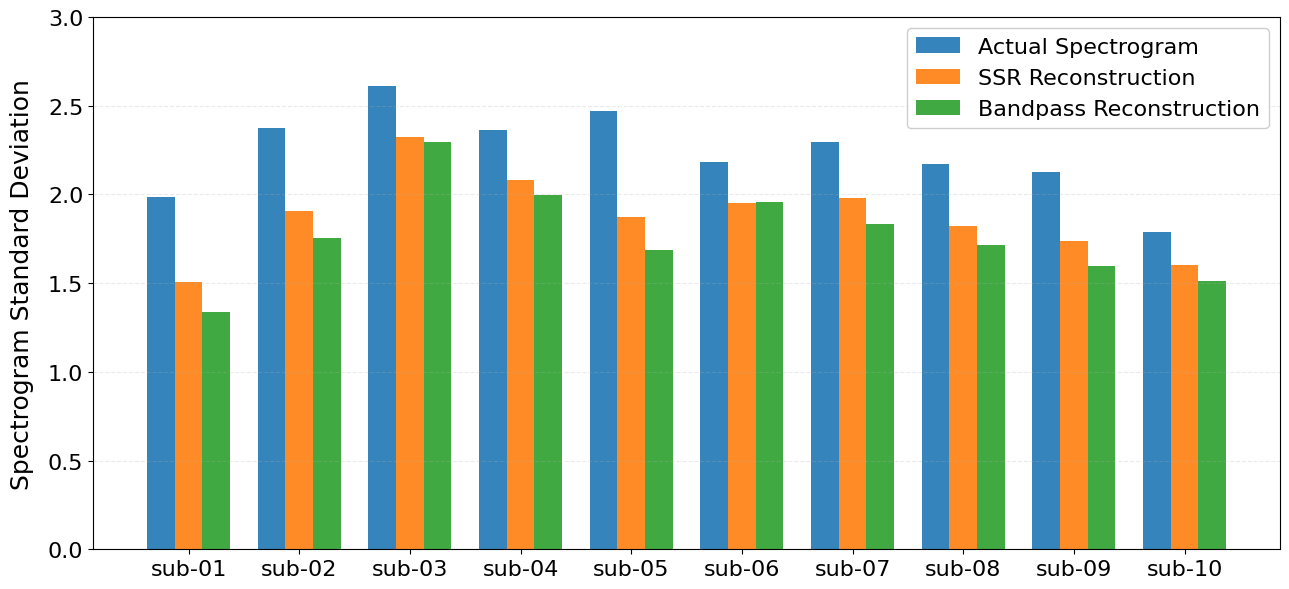

In [19]:
# plots standard deviation of spectrograms comparison


stds_actual = []
stds_bandpass = []
stds_ssr = []

def to_db(x):
    return x#20*np.log10(np.maximum(x, 1e-5))


for pt in pts:
    try:
        spec1_full = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
        spec2 = np.load(os.path.join(result_path, f'{pt}_bandpass_predicted_spec.npy'))
        #spec2 = np.load(os.path.join(result_path, f'{pt}_bandpass_predicted_spec.npy'))
        spec3 = np.load(os.path.join(result_path, f'{pt}_PAC_predicted_spec.npy'))
        spec1 = spec1_full[1000:, :]
        
        db_actual   = to_db(spec1)
        db_bandpass = to_db(spec2)
        db_ssr      = to_db(spec3)
        
        stds_actual.append(db_actual.std())
        stds_bandpass.append(db_bandpass.std())
        stds_ssr.append(db_ssr.std())
    except FileNotFoundError:
        print(f"File missing for {pt}, skipping.")

# Make grouped bar chart
if stds_actual:
    fig, ax = plt.subplots(figsize=(13, 6))
    
    # Set bar positions on x-axis
    x = np.arange(len(stds_actual))
    width = 0.25  
    
    # Plot bars with a publication-safe color palette
    ax.bar(x - width, stds_actual, width, label='Actual Spectrogram', color='C0', alpha=0.9)
    ax.bar(x, stds_ssr, width, label='SSR Reconstruction', color='C1', alpha=0.9)
    ax.bar(x + width, stds_bandpass, width, label='Bandpass Reconstruction', color='C2', alpha=0.9)
    
    # Labels and formatting
    ax.set_ylabel('Spectrogram Standard Deviation', fontsize=18, labelpad=10)
    #ax.set_xlabel('Participant', fontsize=12, labelpad=10)
    ax.set_ylim(0, 3)
    
    ax.set_xticks(x)
    ax.set_xticklabels(pts)
    ax.tick_params(axis='both', labelsize=16)
    
    ax.grid(True, axis='y', alpha=0.25, linestyle='--')
    
    ax.legend(fontsize=16, loc='upper right', framealpha=0.95)

    plt.tight_layout()
    plt.savefig('spectrogram_variance_comparison.png', dpi=300)
    plt.show()
else:
    print("No data extracted. Verify your path definitions.")

In [21]:
#print how much the ssr and bandpass error maps resemble eachother

def to_db(x):
    return x#20 * np.log10(np.maximum(x, 1e-5))
    
for pt in pts:
    print(pt)
    spec1_full = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
    spec2 = np.load(os.path.join(result_path, f'{pt}_bandpass_predicted_spec.npy'))
    spec3 = np.load(os.path.join(result_path, f'{pt}_PAC_predicted_spec.npy'))
    spec1 = spec1_full[1000:, :]

    
    db_actual   = to_db(spec1).T 
    db_bandpass = to_db(spec2).T 
    db_ssr      = to_db(spec3).T 
    
    error_bandpass_raw = np.mean(np.abs(db_actual - db_bandpass), axis=0)
    error_ssr_raw      = np.mean(np.abs(db_actual - db_ssr), axis=0)
    time_axis = np.linspace(10, 300, num=db_actual.shape[1])
    
    error_bandpass_line = error_bandpass_raw
    error_ssr_line      = error_ssr_raw

    r, p = pearsonr(error_bandpass_line,error_ssr_line)
    print(f'pearsonr: {r}')

sub-01
pearsonr: 0.6372014785231919
sub-02
pearsonr: 0.6611001670116036
sub-03
pearsonr: 0.6527210400666918
sub-04
pearsonr: 0.6685374508899075
sub-05
pearsonr: 0.7249354247682966
sub-06
pearsonr: 0.734790950652466
sub-07
pearsonr: 0.7024664531377786
sub-08
pearsonr: 0.6972213198704134
sub-09
pearsonr: 0.7043526483545544
sub-10
pearsonr: 0.7761506310659644


sub-01
sub-02
sub-03
sub-04
sub-05
sub-06
sub-07
sub-08
sub-09
sub-10


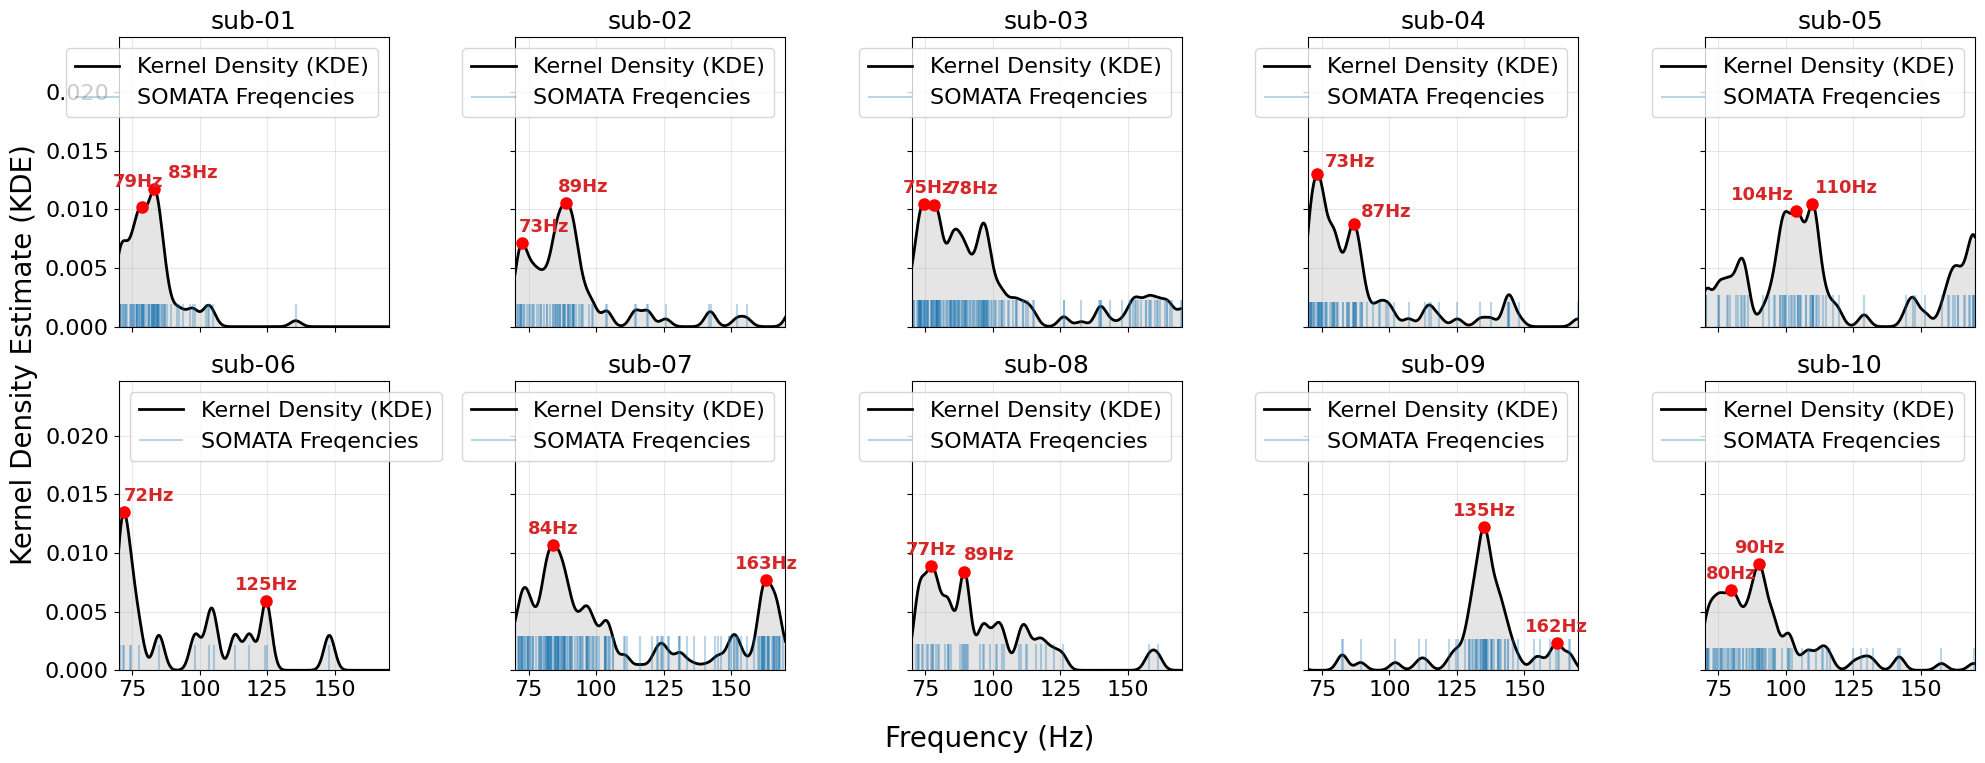

In [26]:
#plot of template frequencies - think i accidentaly deleted the actual one but its about this


%matplotlib inline

# manual offset for peak text so it doesnt overlap
# Format: 'subject_id': { peak_frequency_int: (x_nudge, y_nudge, alignment) }
manual_offsets = {
    'sub-01': {79: (-3, 14, 'center'), 83: (10, 8, 'left')},
    'sub-02': {73: (-3, 8, 'left'), 89: (12, 8, 'center')},
    'sub-03': {75: (3, 8, 'center'), 78: (10, 8, 'left')},
    'sub-04': {73: (5, 5, 'left'), 87: (5, 5, 'left')},
    'sub-05': {104: (-2, 8, 'right'), 110: (2, 8, 'left')},
    'sub-06': {72: (0, 8, 'left'), 125: (0, 8, 'center')},
    'sub-08': {77: (0, 8, 'center'), 89: (0, 8, 'left')}
}


fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

# Save original functions
original_figure = plt.figure
original_show = plt.show
original_annotate = plt.annotate

# Define bypass functions
def dummy_figure(*args, **kwargs):
    return fig 

def dummy_show():
    pass  

def smart_annotate(text, xy, *args, **kwargs):
    current_f = xy[0]
    # Round to matching integer key to handle floating point variations
    f_key = int(round(current_f)) 
    
    # Check if the active subject has a manual adjustment rule for this peak frequency
    current_pt = smart_annotate.active_pt
    if current_pt in manual_offsets and f_key in manual_offsets[current_pt]:
        x_shift, y_shift, align = manual_offsets[current_pt][f_key]
        kwargs['xytext'] = (x_shift, y_shift)
        kwargs['ha'] = align
    else:
        # Default styling for clean, uncrowded peaks
        kwargs['xytext'] = (0, 8)
        kwargs['ha'] = 'center'
        
    return original_annotate(text, xy, *args, **kwargs)


plt.figure = dummy_figure
plt.show = dummy_show
plt.annotate = smart_annotate
plt.rc('legend', fontsize=8)

try:
    for i, pt in enumerate(pts):
        print(pt)
        plt.sca(axes[i]) 
        smart_annotate.active_pt = pt 
        
        # --- Your exact data processing block ---
        somata_results = np.load(os.path.join(path_somata, f'{pt}_somata_results.npy'), allow_pickle=True).item()
        has_hg_osc = set()
        for idx, data in somata_results.items():
            if any(70 <= f <= 170 for f in data['freqs']):
                has_hg_osc.add(idx)
        hg_subset_results = {idx: somata_results[idx] for idx in has_hg_osc}
        
        template_freqs = build_density_template(hg_subset_results, verbose=True)
        
        # Clean up individual subplot appearance
        plt.title(pt, fontsize=18)
        plt.xlim(70, 170)
        
        # Add slight vertical headroom
        ax_ymax = axes[i].get_ylim()[1]
        axes[i].set_ylim(0, ax_ymax*0.95)
        axes[i].tick_params(axis='both', labelsize=16)

finally:
    plt.figure = original_figure
    plt.show = original_show
    plt.annotate = original_annotate


fig.text(0.5, 0.01, 'Frequency (Hz)', ha='center', fontsize=20)
fig.text(0.01, 0.5, 'Kernel Density Estimate (KDE)', va='center', rotation='vertical', fontsize=20)

plt.tight_layout(rect=[0.02, 0.05, 1, 0.95])

plt.savefig(os.path.join(result_path, 'SOMATA_density_templates_all_subjects.png'), dpi=300)
original_show() 

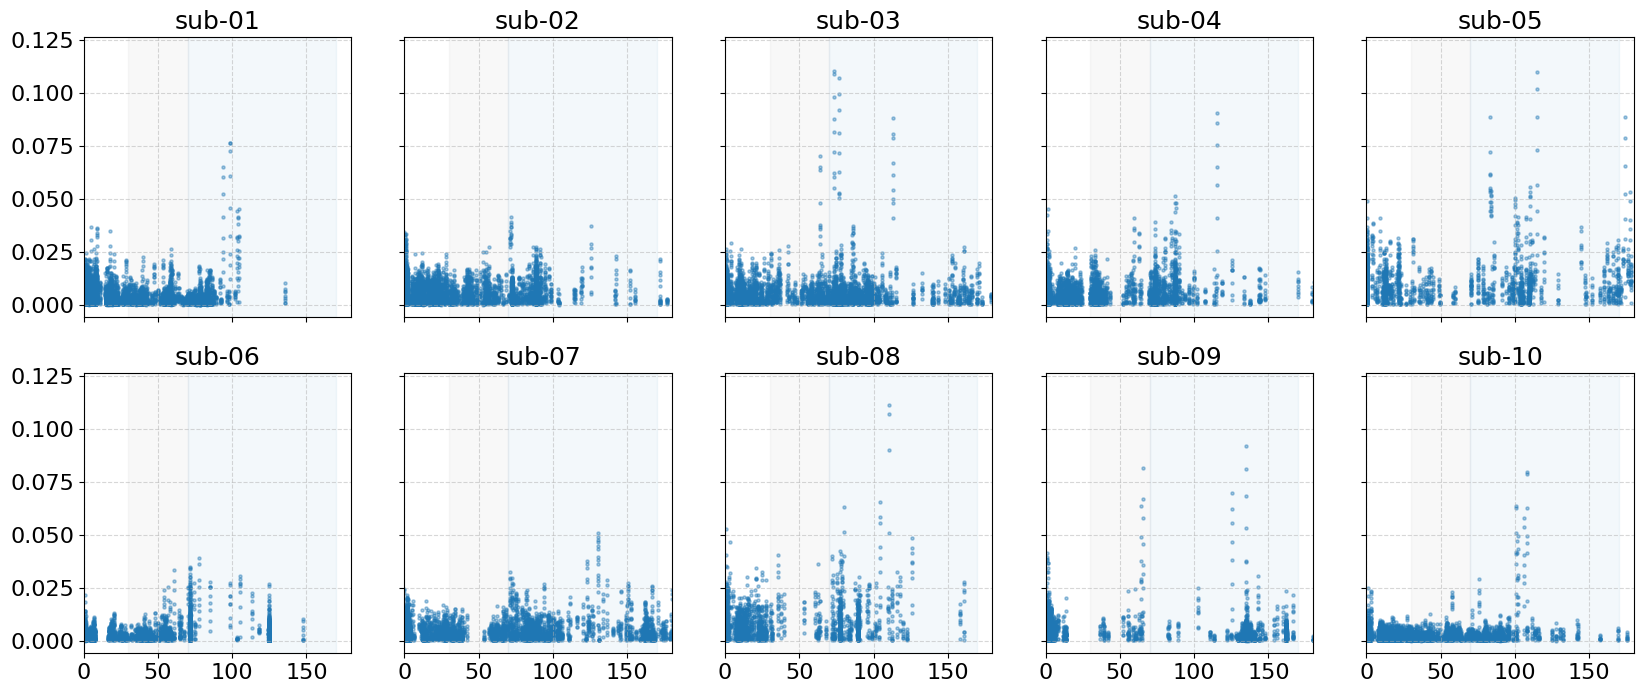

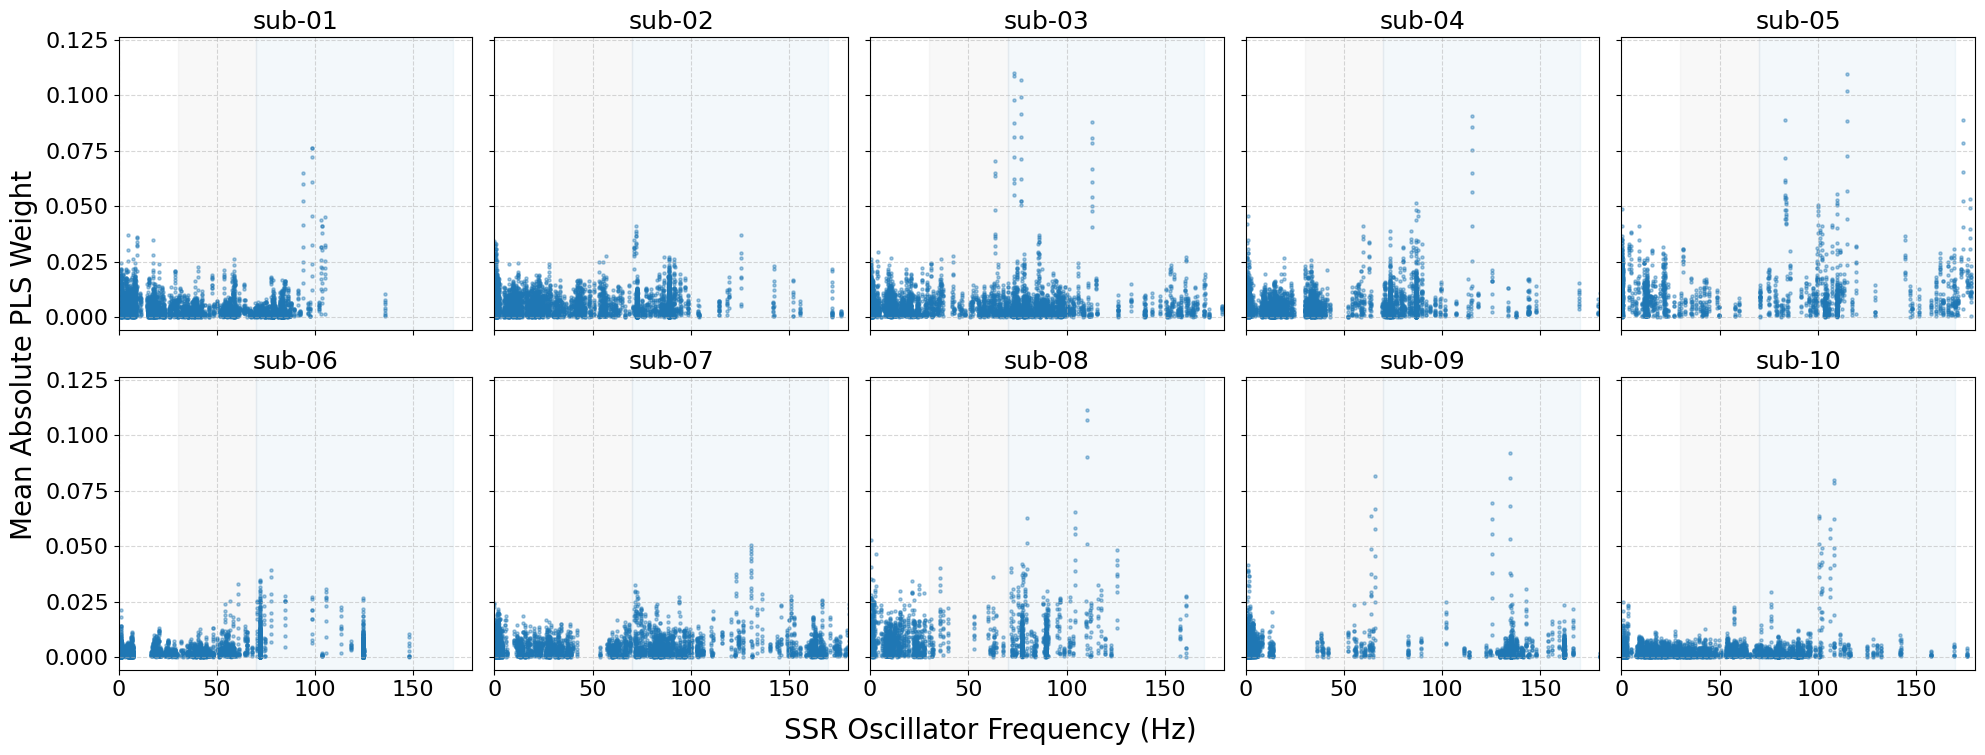

In [12]:
%matplotlib inline

# Helper function to calculate Cohen's d effect size
def cohen_d(x, y):
    nx, ny = len(x), len(y)
    if nx == 0 or ny == 0:
        return 0
    dof = nx + ny - 2
    pooled_std = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / dof)
    if pooled_std == 0:
        return 0
    return (np.mean(x) - np.mean(y)) / pooled_std


# Create a folder to store the extracted data so it doesn't recalculate when rerunning this later
cache_dir = './plot_data_cache'
os.makedirs(cache_dir, exist_ok=True)


fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

for i, pt in enumerate(pts):
    ax = axes[i]

    
    # Define file paths for this specific subject's plot data
    freqs_cache_path = os.path.join(cache_dir, f'{pt}_stacked_freqs.npy')
    importance_cache_path = os.path.join(cache_dir, f'{pt}_importance.npy')
    
    # Check if we already processed and saved this subject's data
    if os.path.exists(freqs_cache_path) and os.path.exists(importance_cache_path):
        # FAST: Just load the weights and frequencies from disk
        all_stacked_freqs = np.load(freqs_cache_path)
        importance = np.load(importance_cache_path)
    else:
        # SLOW: Run the reconstruction pipeline (only happens on the first run)
        r, weights = reconstruct([pt], model='PLS', n_comp=8, feat_suffix='_onlyAMP_SSPEfeat.npy', unstacked=True, saveAs=None)
        
    initParams_list = get_initParams(pt)
    all_osc_freqs = []
    for ch_params in initParams_list:
        all_osc_freqs.extend(ch_params['freqs'])
    
    all_osc_freqs = np.array(all_osc_freqs)
    all_stacked_freqs = np.tile(all_osc_freqs, 9)
    importance = np.mean(np.abs(weights), axis=0)

    print("weights:", weights.shape)
    print("oscillator frequencies:", all_osc_freqs.shape)
    print("stacked frequencies:", all_stacked_freqs.shape)
    print("importance:", np.asarray(importance).shape)
    print("sizes:", np.size(all_stacked_freqs), np.size(importance))


    # Save them now so next time it skips this whole block
    np.save(freqs_cache_path, all_stacked_freqs)
    np.save(importance_cache_path, importance)

    # Draw background HG area shading 
    ax.axvspan(30, 70, color='C7', alpha=0.05, zorder=1)
    ax.axvspan(70, 170, color='C0', alpha=0.05, zorder=1)
    # Plot onto the specific subplot axis
    ax.scatter(all_stacked_freqs, importance, alpha=0.4, s=5, color='C' + str(0)) #blue
    
    ax.set_title(pt, fontsize=18)
    ax.set_xlim([0, 180])
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.tick_params(axis='both', labelsize=16)
    

    clear_output(wait=True)
    display(fig)


fig.text(0.5, 0.02, 'SSR Oscillator Frequency (Hz)', ha='center', fontsize=20)
fig.text(0.01, 0.5, 'Mean Absolute PLS Weight', va='center', rotation='vertical', fontsize=20)

plt.tight_layout(rect=[0.02, 0.05, 1, 0.95])

plt.savefig(os.path.join(result_path, 'PLS_weights_all_subjects_shaded_new.png'), dpi=300)
plt.show()

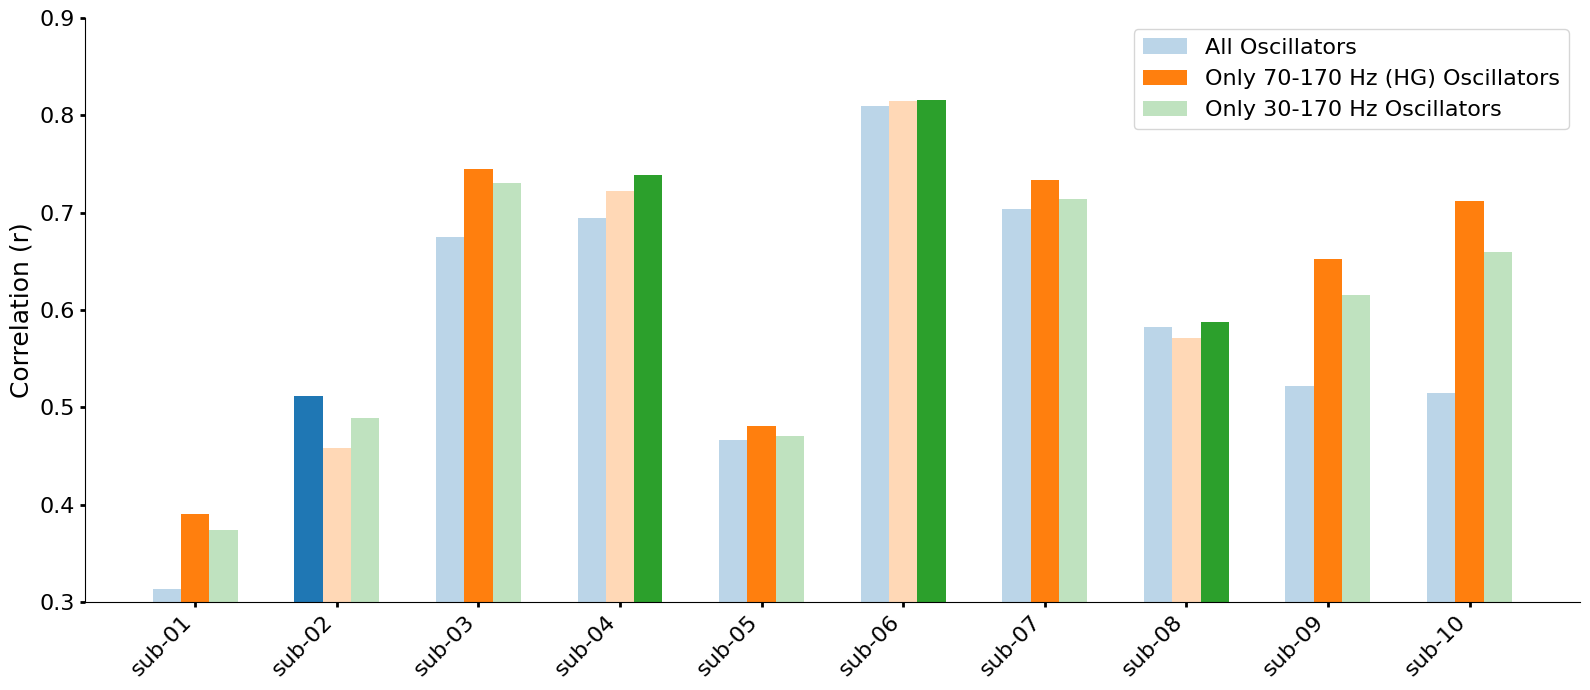

In [24]:

#Performance Comparison with different oscillator selection with linear regression plot

names = [
    'All Oscillators', 
    'Only 70-170 Hz (HG) Oscillators', 
    'Only 30-170 Hz Oscillators'
]

# data is (rows: subjects, columns: models)
data = np.array([
    #[all oscs, 70-170, 30-170]
    [0.3135, 0.3902, 0.3737],  # sub-01
    [0.5115, 0.4581, 0.4894],  # sub-02
    [0.6748, 0.7447, 0.7307],  # sub-03
    [0.6946, 0.7224, 0.7387],  # sub-04
    [0.4661, 0.4805, 0.4709],  # sub-05
    [0.8091, 0.8144, 0.8159],  # sub-06
    [0.7038, 0.7332, 0.7141],  # sub-07
    [0.5827, 0.5708, 0.5881],  # sub-08
    [0.5221, 0.6529, 0.6155],  # sub-09
    [0.5150, 0.7125, 0.6591]   # sub-10
])

# Format data into results structure 
results = [data[:, i].reshape(10, 1, 1) for i in range(3)]

# Calculate means and stds for each model
means = [np.mean(res, axis=(1, 2)) for res in results]
stds = [np.std(res, axis=(1, 2)) for res in results]

# Determine the index of the best model for each subject
means_matrix = np.array(means).T  # Shape: (10 subjects, 3 models)
best_model_indices = np.argmax(means_matrix, axis=1)

# Plotting 
prefixes = names
n_models = len(prefixes)
n_subs = len(means[0])
x = np.arange(n_subs)

# Adjust width and offsets based on number of models
width = 0.2  
offsets = np.linspace(-(width * (n_models - 1) / 2), (width * (n_models - 1) / 2), n_models)

fig, ax = plt.subplots(figsize=(16, 7))

# Plot bars and scatter points subject by subject to change alpha dynamically
for i in range(n_models):
    for p in range(n_subs):
        # Check if model 'i' is the best model for subject 'p'
        is_best = (best_model_indices[p] == i)
        alpha_val = 1.0 if is_best else 0.3  # Fully opaque for best model, transparent for others
        
        # Plot Bars
        ax.bar(p + offsets[i], means[i][p], width,  
               label=names[i] if p == 0 else "", alpha=alpha_val, color=f'C{i}', capsize=3)

# Styling
ax.set_ylabel('Correlation (r)', fontsize=18)
#ax.set_title(title, fontsize=20, pad=20)
ax.set_xticks(x)
ax.set_xticklabels([f'sub-{i+1:02d}' for i in x], rotation=45, ha='right', fontsize=16)

# Set the updated y-axis limits requested
ax.set_ylim(0.3, 0.9)

# Clean up spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=16, width=2)

# Legend and Layout
ax.legend(fontsize=16, loc='upper right')# bbox_to_anchor=(1, 1))
plt.tight_layout()

# Save and Show
result_path = './' 
plt.savefig(os.path.join(result_path, 'osc_selection.png'), dpi=600, bbox_inches='tight')
plt.show()

(23, 1000)
(1000,)


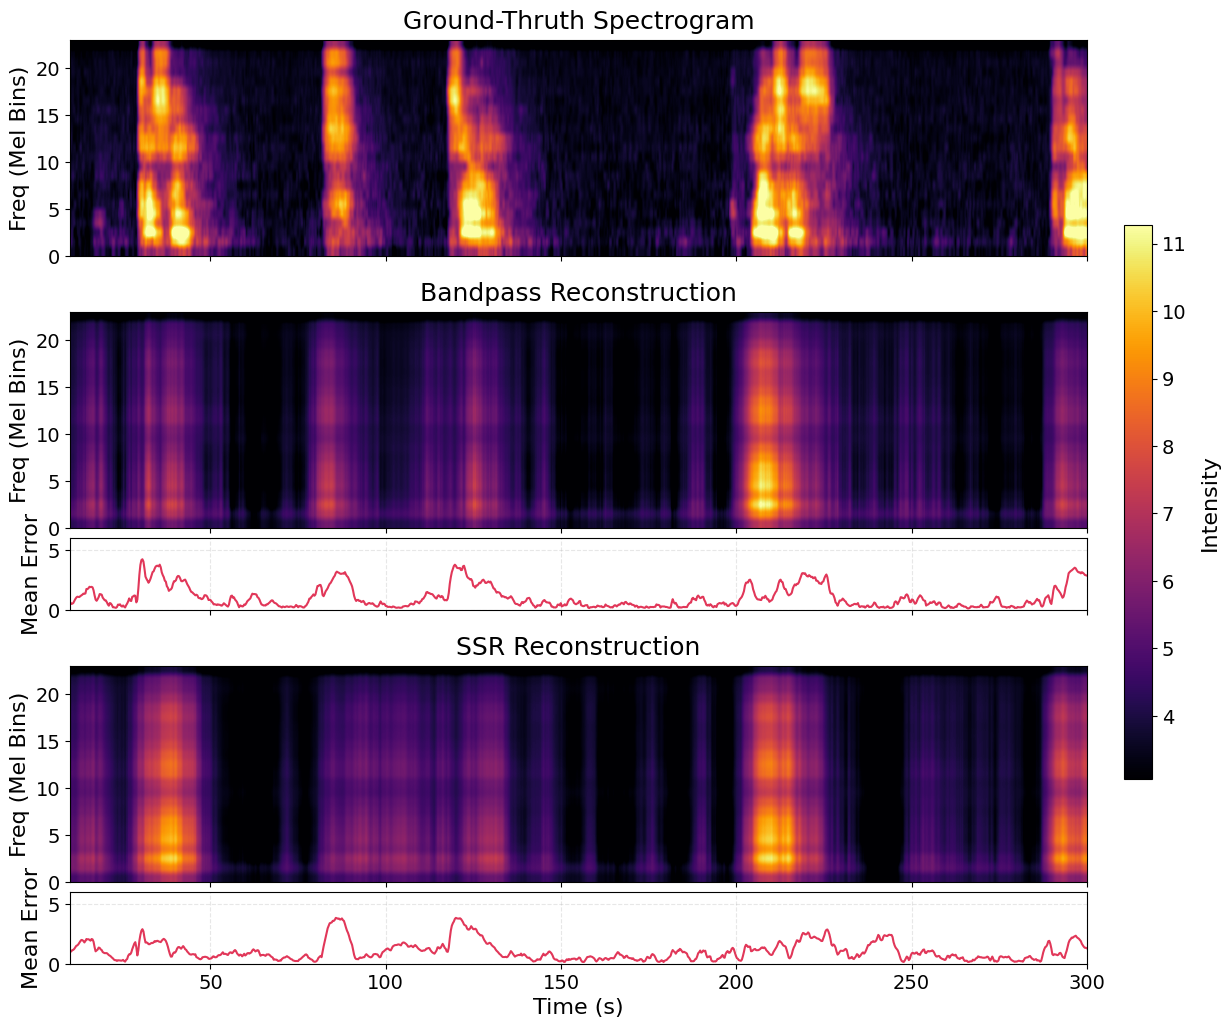

In [4]:
#vertical spectrogram plots
pts = ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05','sub-06','sub-07', 'sub-08', 'sub-09']

pts = ['sub-01']
for pt in pts:
    
    spec1_full = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
    spec2 = np.load(os.path.join(result_path, f'{pt}_bandpass_predicted_spec.npy'))
    spec3 = np.load(os.path.join(result_path, f'{pt}_PAC_predicted_spec.npy'))
    spec1 = spec1_full[1000:, :]


    #i decided to keep it in linear scale (since many values <1) but maybe forgot to do that when making it for each participant in the appendix? 
    '''
    def to_db(x):
        return 20 * np.log10(np.maximum(x, 1e-5)) #replace by x
    
    db_actual   = to_db(spec1).T 
    db_bandpass = to_db(spec2).T 
    db_ssr      = to_db(spec3).T 

    s = 1000
    #i want to see it starting at 27500, or at 7000, with a window of s=1000
    db_actual   = spec1[:s,:].T 
    db_bandpass = spec2[:s,:].T 
    db_ssr      = spec3[:s,:].T
    '''

    s = 1000
    start = 27500  # Change this to 7000 or any other point as needed
    
    # Define the end point of the window
    end = start + s
    
    # Slice the matrix across the time dimension (axis 0) before transposing
    db_actual   = spec1[start:end, :].T 
    db_bandpass = spec2[start:end, :].T 
    db_ssr      = spec3[start:end, :].T

    error_bandpass_raw = np.mean(np.abs(db_actual - db_bandpass), axis=0)
    error_ssr_raw      = np.mean(np.abs(db_actual - db_ssr), axis=0)
    time_axis = np.linspace(10, 300, num=db_actual.shape[1])

    print(db_actual.shape)
    print(error_bandpass_raw.shape)

    '''
    def smooth_line(data, window_size=15):
        window = np.ones(window_size) / window_size
        return np.convolve(data, window, mode='same')
    
    error_bandpass_line = smooth_line(error_bandpass_raw)
    error_ssr_line      = smooth_line(error_ssr_raw)
    '''

    error_bandpass_line = error_bandpass_raw
    error_ssr_line      = error_ssr_raw
    
    # Build the layout grid
    fig, axes = plt.subplots(
        nrows=7, ncols=1, 
        figsize=(16, 12), 
        sharex=True,
        gridspec_kw={'height_ratios': [3, 0.5, 3, 1, 0.5, 3, 1]}
    )
    
    title_font = {'fontsize': 18, 'pad': 8}
    label_font = {'fontsize': 16}
    tick_size = 14
    vmin, vmax = np.percentile(db_actual, 5), np.percentile(db_actual, 99)
    extent_vals = [10, 300, 0, 23]
    
    # plotting the panels:
    # Row 0: Original Spectrogram
    im = axes[0].imshow(db_actual, aspect='auto', origin='lower', cmap='inferno', vmin=vmin, vmax=vmax, extent=extent_vals)
    axes[0].set_title("Ground-Thruth Spectrogram", **title_font)
    axes[0].set_ylabel("Freq (Mel Bins)", **label_font)
    
   # Row 1: white space
    axes[1].axis('off') # Deletes the frame completely, leaving pure white space
    
    # Row 1: Bandpass Spectrogram
    axes[2].imshow(db_bandpass, aspect='auto', origin='lower', cmap='inferno', vmin=vmin, vmax=vmax, extent=extent_vals)
    axes[2].set_title("Bandpass Reconstruction", **title_font)
    axes[2].set_ylabel("Freq (Mel Bins)", **label_font)
    
    # Row 3: Bandpass Error Line
    axes[3].plot(time_axis, error_bandpass_line, color='crimson', linewidth=1.5, alpha=0.85)
    axes[3].set_ylabel("Mean Error", **label_font)
    axes[3].set_ylim(0, 6)
    axes[3].grid(True, alpha=0.3, linestyle='--')
    
    # Row 4: white space
    axes[4].axis('off') #
    
    
    # Row 4: SSR Spectrogram
    axes[5].imshow(db_ssr, aspect='auto', origin='lower', cmap='inferno', vmin=vmin, vmax=vmax, extent=extent_vals)
    axes[5].set_title("SSR Reconstruction", **title_font)
    axes[5].set_ylabel("Freq (Mel Bins)", **label_font)
    
    
    # Row 6: SSR Error Line
    axes[6].plot(time_axis, error_ssr_line, color='crimson', linewidth=1.5, alpha=0.85)
    axes[6].set_ylabel("Mean Error", **label_font)
    axes[6].set_xlabel("Time (s)", **label_font)
    axes[6].set_ylim(0, 6)
    axes[6].grid(True, alpha=0.3, linestyle='--')
    
    
    #global style
    for ax in axes:
        ax.tick_params(labelsize=tick_size)
    
    fig.subplots_adjust(hspace=0.08) 
    
    cbar = fig.colorbar(im, ax=axes.tolist(), label="Intensity", shrink=0.6, pad=0.03)
    cbar.set_label("Intensity", fontsize=16, labelpad=10)
    cbar.ax.tick_params(labelsize=14)
    
    plt.savefig(os.path.join(result_path, f'{pt}_spectograms_vertical.png'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:

# hardcoded recreation of likelihooda and b, since the other plots were printed by a somata function i cant adapt
x_a = [0, 1, 2, 3, 4, 5, 6]
y_a = [-24025, -23400, -22460, -22440, -22450, -22465, -22470]

fig_a, ax_a = plt.subplots(figsize=(4.5, 3.6), dpi=150)
ax_a.plot(x_a, y_a, marker='.', markersize=4, linewidth=1, color='C0', zorder=1)
ax_a.plot(2, -22460, marker='o', markersize=5, color='red', zorder=2) # Red highlight dot

ax_a.set_ylabel("Log Likelihood", fontsize=12, labelpad=4)
ax_a.set_xlabel("Index of Model", fontsize=12, labelpad=4)
ax_a.set_xticks(x_a)
ax_a.set_xticklabels(x_a, fontsize=10)

ax_a.set_ylim(-24100, -22350)
ax_a.set_yticks([-24000, -23800, -23600, -23400, -23200, -23000, -22800, -22600, -22400])
ax_a.set_yticklabels([-24000, -23800, -23600, -23400, -23200, -23000, -22800, -22600, -22400], fontsize=10)

ax_a.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.savefig('likelihooda.png', bbox_inches='tight')
plt.show()


# Recreation of likelihoodb
x_b = [0, 1, 2, 3, 4, 5, 6]
y_b = [-22960, -22660, -22680, -22200, -22185, -22178, -22172]

fig_b, ax_b = plt.subplots(figsize=(4.5, 3.6), dpi=150)
ax_b.plot(x_b, y_b, marker='.', markersize=4, linewidth=1, color='C0', zorder=1)
ax_b.plot(1, -22660, marker='o', markersize=5, color='red', zorder=2) # Red highlight dot

ax_b.set_ylabel("Log Likelihood", fontsize=12, labelpad=4)
ax_b.set_xlabel("Index of Model", fontsize=12, labelpad=4)
ax_b.set_xticks(x_b)
ax_b.set_xticklabels(x_b, fontsize=10)

ax_b.set_ylim(-23000, -22120)
ax_b.set_yticks([-22900, -22800, -22700, -22600, -22500, -22400, -22300, -22200])
ax_b.set_yticklabels([-22900, -22800, -22700, -22600, -22500, -22400, -22300, -22200], fontsize=10)

ax_b.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.savefig('likelihoodb.png', bbox_inches='tight')
plt.show()

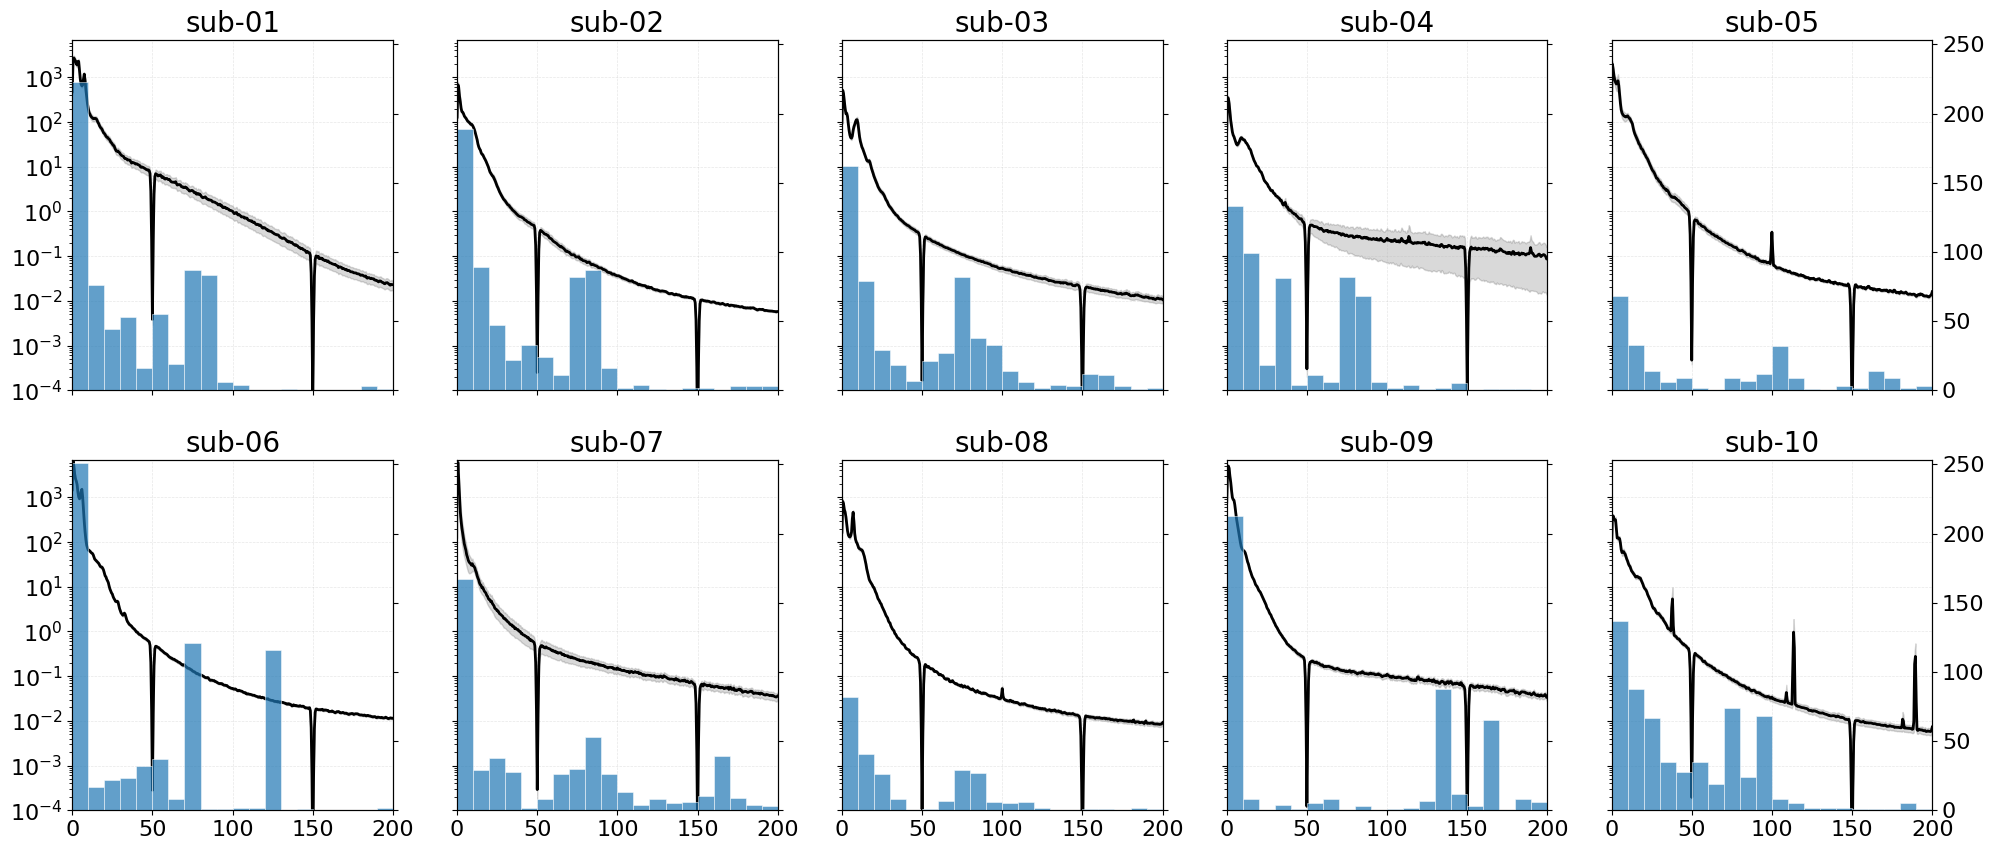

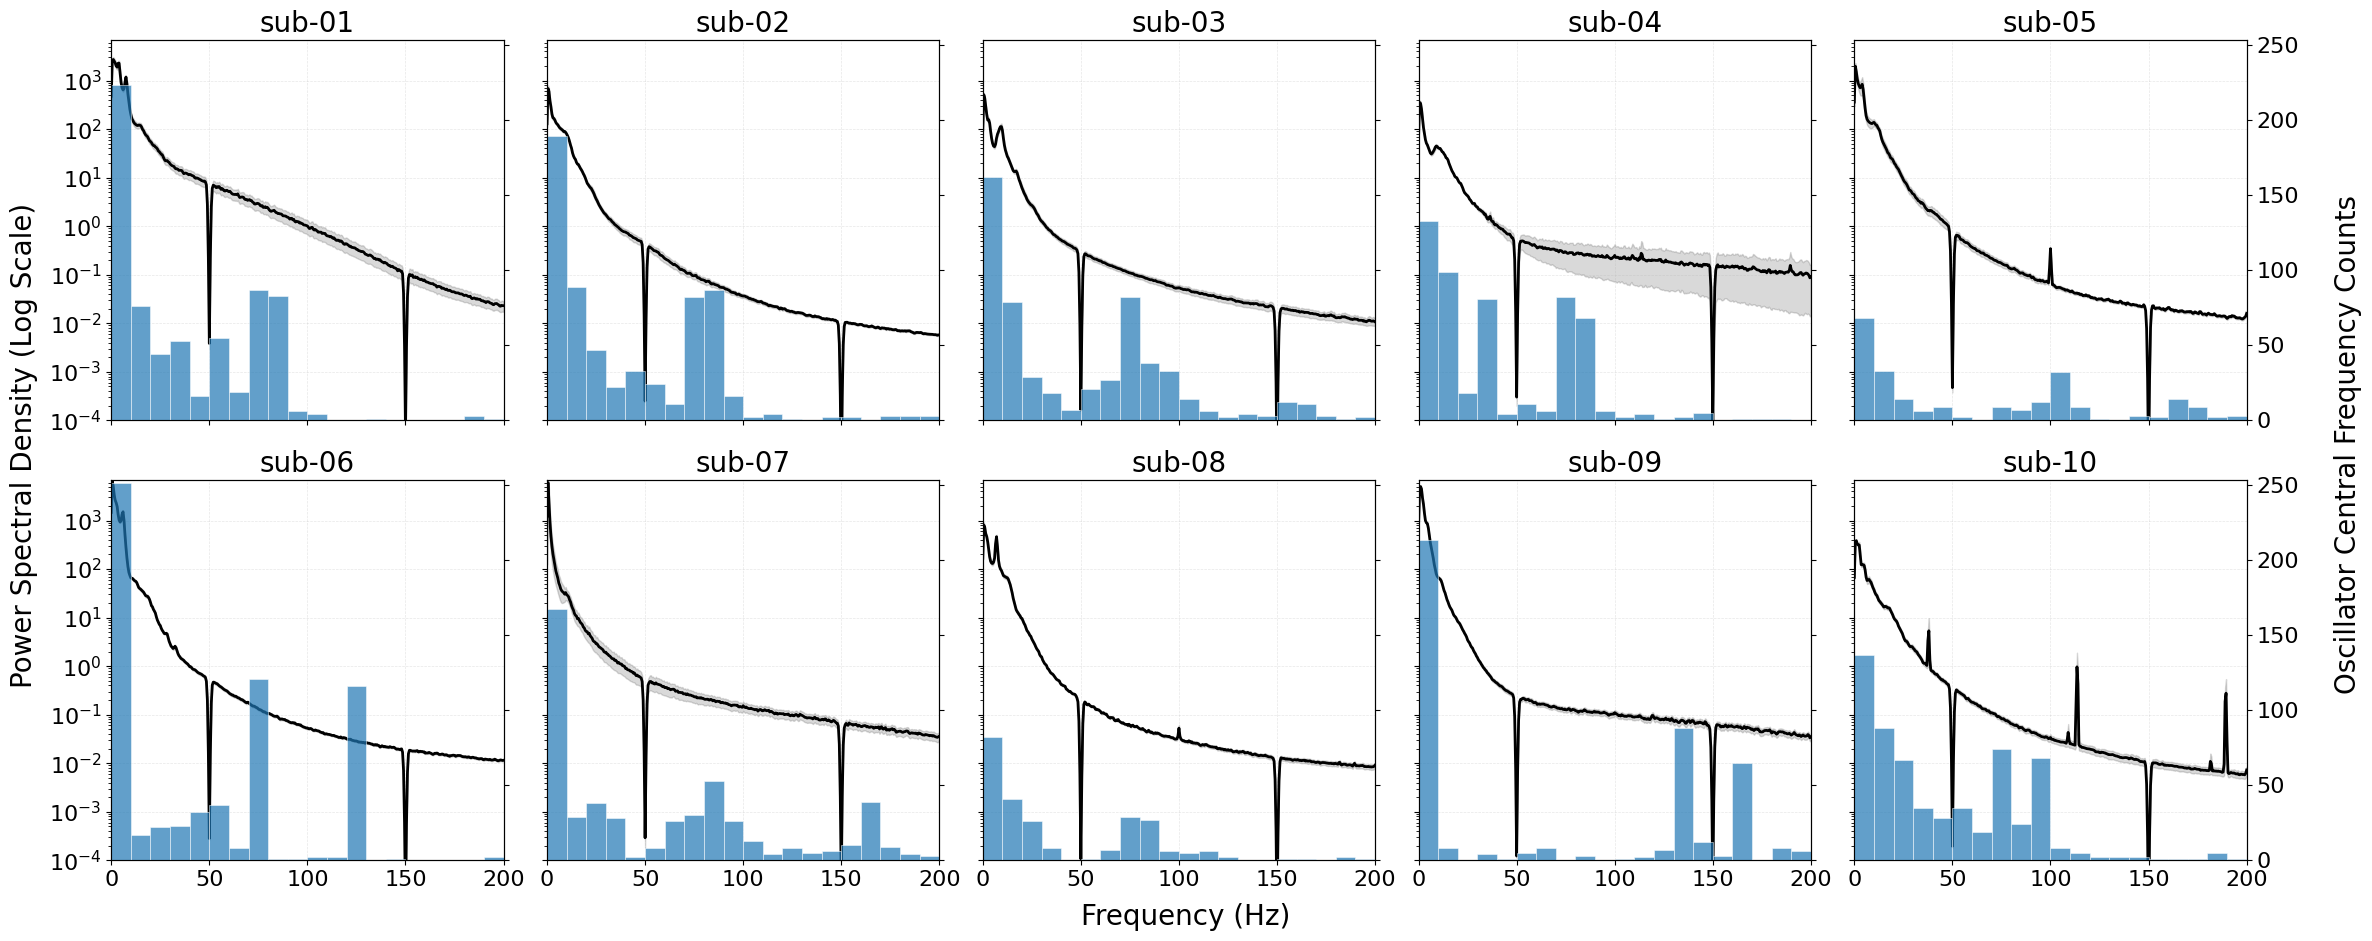

In [23]:
#SSR model fits for all subjects


%matplotlib inline

color_psd = 'black'
color_hist = 'C0'
color_twin_axis = 'black'  

bins = np.arange(0, 201, 10)  # 0 to 200 Hz with 10 Hz bins
nperseg = 2048


# calculate shared y-limits
max_psd_val = 0
max_hist_count = 0

for pt in pts:
    initParams_list = get_initParams(pt)
    freqs = []
    for ch_idx in range(len(initParams_list)):
        freqs.extend(initParams_list[ch_idx]['freqs'])
    
    counts, _ = np.histogram(freqs, bins=bins)
    if len(counts) > 0 and counts.max() > max_hist_count:
        max_hist_count = counts.max()
    
    nwb_path = os.path.join(path_bids, pt, 'ieeg', f'{pt}_task-wordProduction_ieeg.nwb')
    with NWBHDF5IO(nwb_path, 'r') as io:
        nwbfile = io.read()
        raw_ch0 = nwbfile.acquisition['iEEG'].data[:, 0]
    
    for idx in range(0, 5):
        sos = scipy.signal.iirfilter(4, [(idx*100+49)/(sr/2), (idx*100+51)/(sr/2)], btype='bandstop', output='sos')
        raw_ch0 = scipy.signal.sosfiltfilt(sos, raw_ch0, axis=0)
        
    _, psd_ch0 = scipy.signal.welch(raw_ch0, fs=sr, nperseg=nperseg)
    if psd_ch0.max() > max_psd_val:
        max_psd_val = psd_ch0.max()

global_psd_ymax = max_psd_val * 1.2
global_hist_ymax = max_hist_count + 2  
print(f"Limits calculated -> Global PSD Ceiling: {global_psd_ymax:.2e}, Global Hist Ceiling: {global_hist_ymax}")


#plotting
fig, axes = plt.subplots(2, 5, figsize=(24, 10), sharex=True)
axes = axes.flatten()

for i, pt in enumerate(pts):
    ax1 = axes[i]
    
    # Collect Oscillator Central Frequencies
    initParams_list = get_initParams(pt) 
    num_channels = len(initParams_list)
    
    all_fitted_freqs = []
    for ch_idx in range(num_channels):
        freqs = initParams_list[ch_idx]['freqs']
        all_fitted_freqs.extend(freqs)
    all_fitted_freqs = np.array(all_fitted_freqs)
    
    # Load Raw iEEG Data and Compute PSD
    nwb_path = os.path.join(path_bids, pt, 'ieeg', f'{pt}_task-wordProduction_ieeg.nwb')
    with NWBHDF5IO(nwb_path, 'r') as io:
        nwbfile = io.read()
        raw_data = nwbfile.acquisition['iEEG'].data[:]

    # Remove (harmonics of) line noise
    for idx in range(0, 5):
        sos = scipy.signal.iirfilter(4, [(idx*100+49)/(sr/2), (idx*100+51)/(sr/2)], btype='bandstop', output='sos')
        raw_data = scipy.signal.sosfiltfilt(sos, raw_data, axis=0)
    
    full_freq_axis, temp_psd = scipy.signal.welch(raw_data[:, 0], fs=sr, nperseg=nperseg)
    freq_mask = (full_freq_axis >= 0) & (full_freq_axis <= 200)
    freq_axis = full_freq_axis[freq_mask]
    
    all_psds = np.zeros((len(freq_axis), num_channels))
    for ch_idx in range(num_channels):
        _, psd = scipy.signal.welch(raw_data[:, ch_idx], fs=sr, nperseg=nperseg)
        all_psds[:, ch_idx] = psd[freq_mask]
        
    grand_avg_psd = np.mean(all_psds, axis=1)
    sem_psd = all_psds.std(axis=1) / np.sqrt(num_channels)
    
    # --- 3. Plotting Empirical PSD (Left Axis) ---
    ax1.plot(freq_axis, grand_avg_psd, color=color_psd, linewidth=2, label='Grand Avg PSD' if i==0 else "")
    ax1.fill_between(freq_axis, grand_avg_psd - sem_psd, grand_avg_psd + sem_psd, 
                     color=color_psd, alpha=0.15)
    ax1.set_yscale('log')
    ax1.set_xlim([0, 200])
    ax1.set_ylim([10**-4, global_psd_ymax])
    ax1.grid(True, which='major', linestyle='--', linewidth=0.5, alpha=0.3)
    ax1.set_title(pt, fontsize=20)
    
    # Hide all left labels except on plot 1 (index 0) and plot 6 (index 5)
    if i == 0 or i == 5:
        ax1.tick_params(axis='y', labelcolor=color_psd, labelsize=16) 
    else:
        ax1.tick_params(axis='y', labelleft=False)
        
    ax1.tick_params(axis='x', labelsize=16)
    
    # Plotting Oscillator Distribution (Right Axis)
    ax2 = ax1.twinx()  
    ax2.hist(all_fitted_freqs, bins=bins, color=color_hist, alpha=0.7, edgecolor='white', linewidth=0.5, label='Fitted Oscillators' if i==0 else "")
    ax2.set_ylim([0, global_hist_ymax])
    ax2.spines['right'].set_color(color_twin_axis)
    
    # Hide all right labels exceot on plot 5 (index 4) and plot 10 (index 9)
    if i == 4 or i == 9:
        ax2.tick_params(axis='y', labelcolor=color_twin_axis, labelsize=16)
    else:
        ax2.tick_params(axis='y', labelright=False)

    # --- 5. Real-Time Dashboard Trick ---
    clear_output(wait=True)
    display(fig)

# global labels and legend
fig.text(0.5, 0.02, 'Frequency (Hz)', ha='center', fontsize=20)
fig.text(0.01, 0.5, 'Power Spectral Density (Log Scale)', va='center', rotation='vertical', fontsize=20, color=color_psd)
fig.text(0.99, 0.5, 'Oscillator Central Frequency Counts', va='center', rotation='vertical', fontsize=20, color=color_twin_axis, ha='right')


plt.tight_layout(rect=[0.02, 0.04, 0.97, 0.95])

plt.savefig(os.path.join(result_path, 'SSR_model_fits_all_subjects.png'), dpi=300)
plt.show()

0.6846


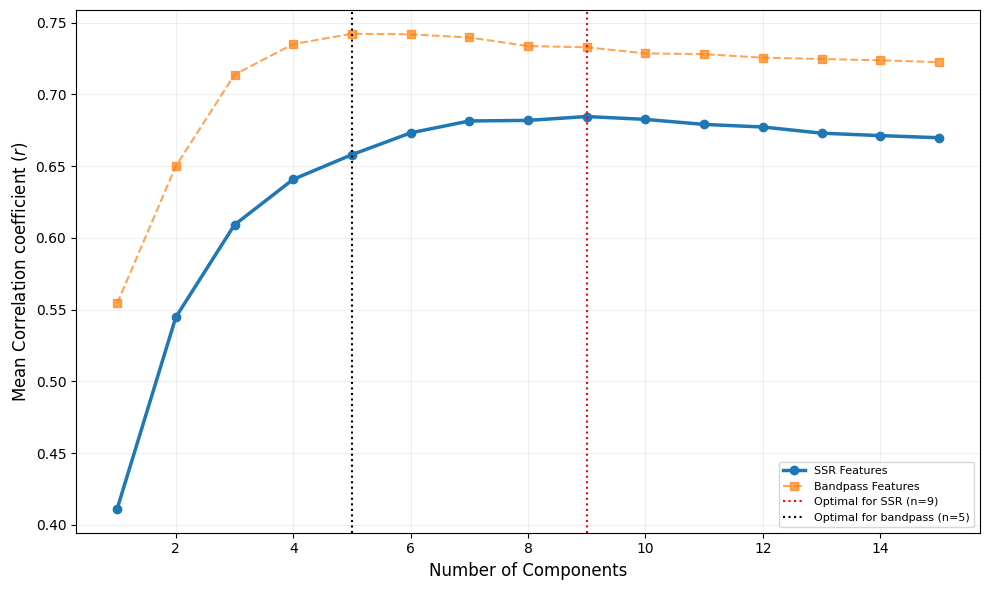

In [28]:
#pls hyperparameter tuning


#didnt save the result in a file so i got this from the printed output of the cell in the PLS tuning notebook

raw_data = [
    0.278716, 0.393264, 0.511073, 0.571334, 0.317257, 0.336599, 0.429360, 0.451308, 0.243604, 0.457570, # n=1 SSPE
    0.383461, 0.560944, 0.722987, 0.615082, 0.429315, 0.773503, 0.463252, 0.680421, 0.273792, 0.544120, # n=1 BP
    0.404570, 0.480909, 0.652646, 0.670584, 0.411084, 0.707795, 0.628390, 0.585415, 0.413108, 0.492016, # n=2 SSPE
    0.488441, 0.610807, 0.796186, 0.755545, 0.512079, 0.852174, 0.613257, 0.700362, 0.455714, 0.612138, # n=2 BP
    0.450636, 0.546746, 0.710191, 0.715544, 0.442933, 0.773243, 0.690367, 0.573119, 0.533545, 0.550861, # n=3 SSPE
    0.550954, 0.630765, 0.836686, 0.781300, 0.545463, 0.861882, 0.675692, 0.710910, 0.622647, 0.694452, # n=3 BP
    0.497362, 0.564652, 0.731244, 0.750419, 0.502280, 0.786704, 0.700430, 0.584473, 0.590284, 0.598311, # n=4 SSPE
    0.564859, 0.646446, 0.841922, 0.785861, 0.569378, 0.866255, 0.700773, 0.716723, 0.653418, 0.702160, # n=4 BP
    0.520780, 0.593527, 0.752416, 0.775714, 0.523549, 0.801115, 0.723134, 0.592444, 0.608746, 0.619954, # n=5 SSPE
    0.585701, 0.649651, 0.844552, 0.793846, 0.576306, 0.869093, 0.709510, 0.716883, 0.668433, 0.704229, # n=5 BP
    0.539350, 0.597928, 0.764781, 0.782141, 0.523622, 0.811373, 0.739862, 0.605515, 0.640300, 0.641628, # n=6 SSPE
    0.593615, 0.647751, 0.842814, 0.794639, 0.573370, 0.868753, 0.728290, 0.715410, 0.683389, 0.703290, # n=6 BP
    0.545577, 0.594753, 0.772392, 0.788242, 0.535259, 0.817606, 0.749891, 0.611714, 0.660078, 0.649998, # n=7 SSPE
    0.596353, 0.644572, 0.839863, 0.792326, 0.573993, 0.867384, 0.734068, 0.712281, 0.689264, 0.699081, # n=7 BP
    0.547407, 0.595329, 0.771673, 0.784176, 0.534302, 0.819349, 0.747860, 0.613054, 0.671664, 0.652315, # n=8 SSPE
    0.597697, 0.641499, 0.836140, 0.791508, 0.568963, 0.867437, 0.745855, 0.709842, 0.691304, 0.692883, # n=8 BP
    0.548866, 0.590674, 0.771208, 0.779386, 0.536557, 0.824812, 0.750376, 0.608173, 0.673381, 0.662176, # n=9 SSPE
    0.596009, 0.640852, 0.834589, 0.790965, 0.566431, 0.866457, 0.747233, 0.708892, 0.697047, 0.689011, # n=9 BP
    0.549441, 0.583430, 0.767393, 0.776906, 0.537265, 0.826168, 0.747097, 0.610063, 0.675638, 0.659678, # n=10 SSPE
    0.595543, 0.636524, 0.833814, 0.791562, 0.561394, 0.865485, 0.746718, 0.708016, 0.696914, 0.686272, # n=10 BP
    0.549798, 0.579193, 0.762948, 0.775994, 0.546417, 0.828126, 0.743149, 0.610767, 0.678783, 0.652477, # n=11 SSPE
    0.595948, 0.635219, 0.832362, 0.791836, 0.560094, 0.864751, 0.746726, 0.707446, 0.696962, 0.685773, # n=11 BP
    0.548615, 0.572875, 0.757621, 0.772025, 0.537383, 0.829973, 0.739586, 0.614543, 0.681326, 0.656672, # n=12 SSPE
    0.597287, 0.633989, 0.831010, 0.788237, 0.559771, 0.863738, 0.746898, 0.705882, 0.697445, 0.682337, # n=12 BP
    0.544326, 0.563889, 0.752950, 0.771870, 0.531685, 0.830324, 0.737575, 0.615128, 0.684286, 0.648832, # n=13 SSPE
    0.596178, 0.632022, 0.830146, 0.786977, 0.559027, 0.862926, 0.746770, 0.704804, 0.696518, 0.679136, # n=13 BP
    0.541133, 0.565066, 0.747565, 0.767758, 0.529605, 0.828915, 0.734720, 0.613411, 0.683537, 0.649444, # n=14 SSPE
    0.594080, 0.630240, 0.829192, 0.786195, 0.557829, 0.862377, 0.746050, 0.704132, 0.694318, 0.675697, # n=14 BP
    0.538431, 0.562616, 0.743341, 0.765477, 0.520681, 0.828013, 0.730806, 0.611926, 0.683238, 0.652625, # n=15 SSPE
    0.591944, 0.626494, 0.828997, 0.785363, 0.557823, 0.862156, 0.746379, 0.703547, 0.691249, 0.673527  # n=15 BP
]
sspe_means = np.array([
    0.4110, # n=1
    0.5447, # n=2
    0.6091, # n=3
    0.6408, # n=4
    0.6580, # n=5
    0.6732, # n=6
    0.6815, # n=7
    0.6819, # n=8
    0.6846, # n=9
    0.6826, # n=10
    0.6791, # n=11
    0.6773, # n=12
    0.6730, # n=13
    0.6713, # n=14
    0.6698  # n=15
])

bp_means = np.array([
    0.5543, # n=1
    0.6500, # n=2
    0.7138, # n=3
    0.7351, # n=4
    0.7423, # n=5
    0.7419, # n=6
    0.7397, # n=7
    0.7337, # n=8
    0.7329, # n=9
    0.7286, # n=10
    0.7281, # n=11
    0.7256, # n=12
    0.7247, # n=13
    0.7238, # n=14
    0.7225  # n=15
])
n_comps = np.arange(1, 16)
print(np.max(sspe_means))
plt.figure(figsize=(10, 6))

plt.plot(n_comps, sspe_means, label='SSR Features', marker='o', linewidth=2.5)
plt.plot(n_comps, bp_means, label='Bandpass Features', linestyle='--', marker='s', alpha=0.7)

# Highlight the optimal choice
plt.axvline(9, color='red', linestyle=':', label='Optimal for SSR (n=9)')
plt.axvline(5, color='black', linestyle=':', label='Optimal for bandpass (n=5)')

#plt.title('Hyperparameter Search for Optimal Number of COmponents$', fontsize=14)
plt.xlabel('Number of Components', fontsize=12)
plt.ylabel('Mean Correlation coefficient ($r$)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(os.path.join(result_path, 'opt_n_components.png'))
plt.show()

[1/45] HG bandpass baseline, n_comp=3
sub-01 has mean correlation of 0.629025
sub-02 has mean correlation of 0.697941
sub-03 has mean correlation of 0.780522
sub-04 has mean correlation of 0.810825
sub-05 has mean correlation of 0.562072
sub-06 has mean correlation of 0.853752
sub-07 has mean correlation of 0.666830
sub-08 has mean correlation of 0.741095
sub-09 has mean correlation of 0.701360
sub-10 has mean correlation of 0.671971
    mean r=0.711539, shape=(10, 10, 23), elapsed=121.3s
[2/45] HG bandpass baseline, n_comp=4
sub-01 has mean correlation of 0.656475
sub-02 has mean correlation of 0.705470
sub-03 has mean correlation of 0.790073
sub-04 has mean correlation of 0.815553
sub-05 has mean correlation of 0.573777
sub-06 has mean correlation of 0.857585
sub-07 has mean correlation of 0.687870
sub-08 has mean correlation of 0.743695
sub-09 has mean correlation of 0.715550
sub-10 has mean correlation of 0.680003
    mean r=0.722605, shape=(10, 10, 23), elapsed=133.2s
[3/45] HG ba

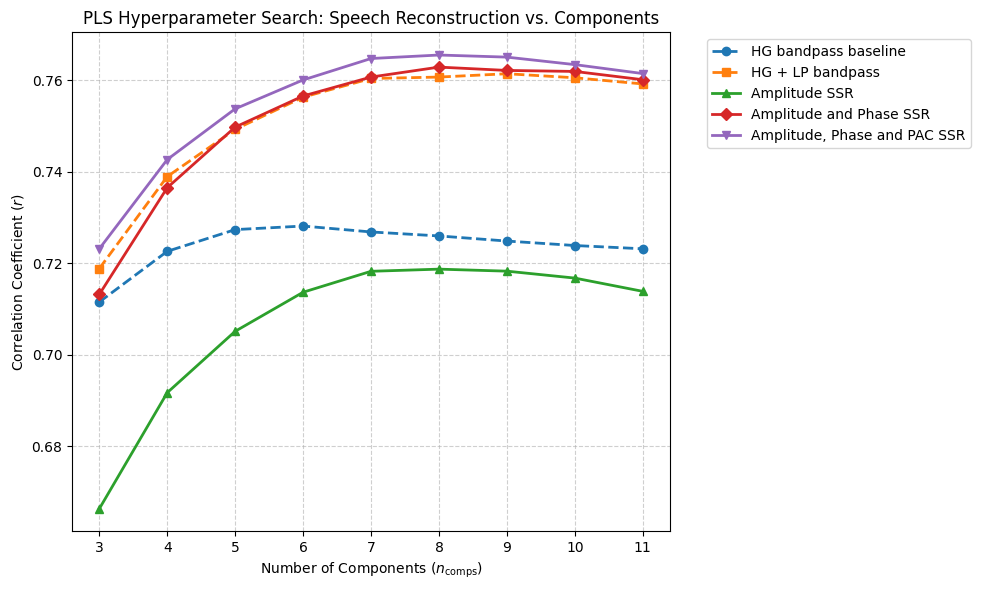

In [2]:
import csv
import gc
import os
import re
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------

n_comps_list = list(range(3, 12))

models_info = {
    "HG bandpass baseline": "_final_bandpass_hg.npy",
    "HG + LP bandpass": "_final_bandpass_hg_lp.npy",
    "Amplitude SSR": "_onlyAMP_SSPEfeat.npy",
    "Amplitude and Phase SSR": "_PHASE_SSPEfeat.npy",
    "Amplitude, Phase and PAC SSR": "_PCA_SSPEfeat.npy",
}

output_dir = Path("pls_hyperparameter_results")
raw_dir = output_dir / "raw_results"

output_dir.mkdir(parents=True, exist_ok=True)
raw_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = output_dir / "search_checkpoint.npz"
scores_csv_path = output_dir / "search_scores.csv"
optimal_csv_path = output_dir / "optimal_components.csv"
plot_path = output_dir / "pls_hyperparameter_search.png"

model_names = list(models_info)
n_models = len(model_names)
n_components = len(n_comps_list)


# ---------------------------------------------------------------------
# Saving and cleanup utilities
# ---------------------------------------------------------------------

def safe_name(text):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text).strip("_")


def atomic_save_npy(path, array):
    """Save without leaving a partially written final file."""
    temporary_path = path.with_suffix(".tmp.npy")
    np.save(temporary_path, array, allow_pickle=False)
    os.replace(temporary_path, path)


def save_checkpoint(scores, completed):
    """Save the complete search state after every reconstruction."""
    temporary_path = checkpoint_path.with_suffix(".tmp.npz")

    np.savez(
        temporary_path,
        model_names=np.asarray(model_names),
        n_comps=np.asarray(n_comps_list, dtype=int),
        scores=scores,
        completed=completed,
    )

    os.replace(temporary_path, checkpoint_path)


def save_scores_csv(scores, completed):
    temporary_path = scores_csv_path.with_suffix(".tmp.csv")

    with temporary_path.open("w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(
            ["model", "feature_suffix", "n_comp", "mean_r", "completed"]
        )

        for model_index, model_name in enumerate(model_names):
            for component_index, n_comp in enumerate(n_comps_list):
                is_completed = bool(completed[model_index, component_index])
                score = (
                    float(scores[model_index, component_index])
                    if is_completed
                    else ""
                )

                writer.writerow(
                    [
                        model_name,
                        models_info[model_name],
                        n_comp,
                        score,
                        is_completed,
                    ]
                )

    os.replace(temporary_path, scores_csv_path)


def cleanup_memory():
    """Release Python references, figures, and optional PyTorch GPU cache."""
    plt.close("all")
    gc.collect()

    # Do not import PyTorch just for cleanup, because importing it uses memory.
    torch = sys.modules.get("torch")
    if torch is not None:
        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        except Exception:
            pass


# ---------------------------------------------------------------------
# Mean calculation
# ---------------------------------------------------------------------

def calculate_mean_r(all_res):
    """
    all_res shape:
        (n_participants, n_folds, n_mel_bins)

    First average folds/bins within each participant, then average the
    participant means. This gives every participant equal weight.
    """
    array = np.asarray(all_res)

    if array.ndim != 3:
        raise ValueError(
            f"Expected a 3-D result array, but received shape {array.shape}."
        )

    if not np.issubdtype(array.dtype, np.number):
        raise TypeError(f"Expected numeric results, but received {array.dtype}.")

    if np.iscomplexobj(array):
        raise TypeError("Correlation coefficients must not be complex.")

    # Avoid a conversion/copy when reconstruct already returns floating point.
    if not np.issubdtype(array.dtype, np.floating):
        array = array.astype(np.float64, copy=False)

    if np.isinf(array).any():
        raise ValueError("The reconstruction result contains infinite values.")

    participant_means = np.empty(array.shape[0], dtype=np.float64)

    for participant_index in range(array.shape[0]):
        participant_values = array[participant_index]

        if np.isnan(participant_values).all():
            raise ValueError(
                f"Participant {participant_index} contains only NaN values."
            )

        participant_means[participant_index] = np.nanmean(
            participant_values
        )

    mean_r = float(np.nanmean(participant_means))

    if not np.isfinite(mean_r):
        raise ValueError("The calculated overall mean is not finite.")

    return mean_r


# ---------------------------------------------------------------------
# Load or initialize checkpoint
# ---------------------------------------------------------------------

if checkpoint_path.exists():
    with np.load(checkpoint_path, allow_pickle=False) as checkpoint:
        saved_models = checkpoint["model_names"].tolist()
        saved_components = checkpoint["n_comps"].tolist()

        if saved_models != model_names:
            raise ValueError(
                "Checkpoint model names do not match the current configuration."
            )

        if saved_components != n_comps_list:
            raise ValueError(
                "Checkpoint component values do not match the current search."
            )

        scores = checkpoint["scores"].astype(np.float64, copy=True)
        completed = checkpoint["completed"].astype(bool, copy=True)

    expected_shape = (n_models, n_components)

    if scores.shape != expected_shape or completed.shape != expected_shape:
        raise ValueError(
            f"Invalid checkpoint shape. Expected {expected_shape}, "
            f"received scores={scores.shape}, completed={completed.shape}."
        )

    print(
        f"Resuming: {completed.sum()} of {completed.size} "
        "combinations are already complete."
    )
else:
    scores = np.full((n_models, n_components), np.nan, dtype=np.float64)
    completed = np.zeros((n_models, n_components), dtype=bool)


# ---------------------------------------------------------------------
# Hyperparameter search
# ---------------------------------------------------------------------

total_runs = completed.size

for model_index, (model_name, feat_suffix) in enumerate(models_info.items()):
    for component_index, n_comp in enumerate(n_comps_list):

        if completed[model_index, component_index]:
            continue

        run_number = int(completed.sum()) + 1
        start_time = time.perf_counter()

        print(
            f"[{run_number}/{total_runs}] "
            f"{model_name}, n_comp={n_comp}",
            flush=True,
        )

        try:
            # Indexing [0] avoids retaining the unused second return value.
            all_res = reconstruct(
                None,
                model="PLS",
                n_comp=n_comp,
                feat_suffix=feat_suffix,
                unstacked=True,
            )[0]

            all_res = np.asarray(all_res)

            if all_res.ndim != 3:
                raise ValueError(
                    f"{model_name}, n_comp={n_comp}: expected shape "
                    f"(participants, folds, mel bins), received {all_res.shape}."
                )

            mean_r = calculate_mean_r(all_res)

            # The filename is unique, so later calls cannot overwrite it.
            raw_path = raw_dir / (
                f"{safe_name(model_name)}__ncomp_{n_comp:02d}.npy"
            )
            atomic_save_npy(raw_path, all_res)

            scores[model_index, component_index] = mean_r
            completed[model_index, component_index] = True

            # Persist progress immediately.
            save_checkpoint(scores, completed)
            save_scores_csv(scores, completed)

            elapsed = time.perf_counter() - start_time
            print(
                f"    mean r={mean_r:.6f}, "
                f"shape={all_res.shape}, elapsed={elapsed:.1f}s",
                flush=True,
            )

        finally:
            # Explicitly remove the potentially large result before GC.
            if "all_res" in locals():
                del all_res

            cleanup_memory()


# ---------------------------------------------------------------------
# Select optimal component counts
# ---------------------------------------------------------------------

print("\n--- Optimal PLS Components ---")

optimal_components = {}

temporary_optimal_path = optimal_csv_path.with_suffix(".tmp.csv")

with temporary_optimal_path.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["model", "best_n_comp", "best_mean_r"])

    for model_index, model_name in enumerate(model_names):
        model_scores = scores[model_index]

        if not np.isfinite(model_scores).any():
            raise ValueError(f"No valid scores are available for {model_name}.")

        best_index = int(np.nanargmax(model_scores))
        best_n_comp = n_comps_list[best_index]
        best_score = float(model_scores[best_index])

        optimal_components[model_name] = best_n_comp
        writer.writerow([model_name, best_n_comp, best_score])

        print(
            f"{model_name}: best n_comp={best_n_comp} "
            f"(mean r={best_score:.4f})"
        )

os.replace(temporary_optimal_path, optimal_csv_path)


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------

markers = ["o", "s", "^", "D", "v"]
linestyles = ["--", "--", "-", "-", "-"]

fig, ax = plt.subplots(figsize=(10, 6))

for model_index, model_name in enumerate(model_names):
    ax.plot(
        n_comps_list,
        scores[model_index],
        label=model_name,
        marker=markers[model_index],
        linestyle=linestyles[model_index],
        linewidth=2,
    )

ax.set_xlabel(r"Number of Components ($n_{\mathrm{comps}}$)")
ax.set_ylabel(r"Correlation Coefficient ($r$)")
ax.set_title("PLS Hyperparameter Search: Speech Reconstruction vs. Components")
ax.set_xticks(n_comps_list)
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(True, linestyle="--", alpha=0.6)

fig.tight_layout()
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

cleanup_memory()

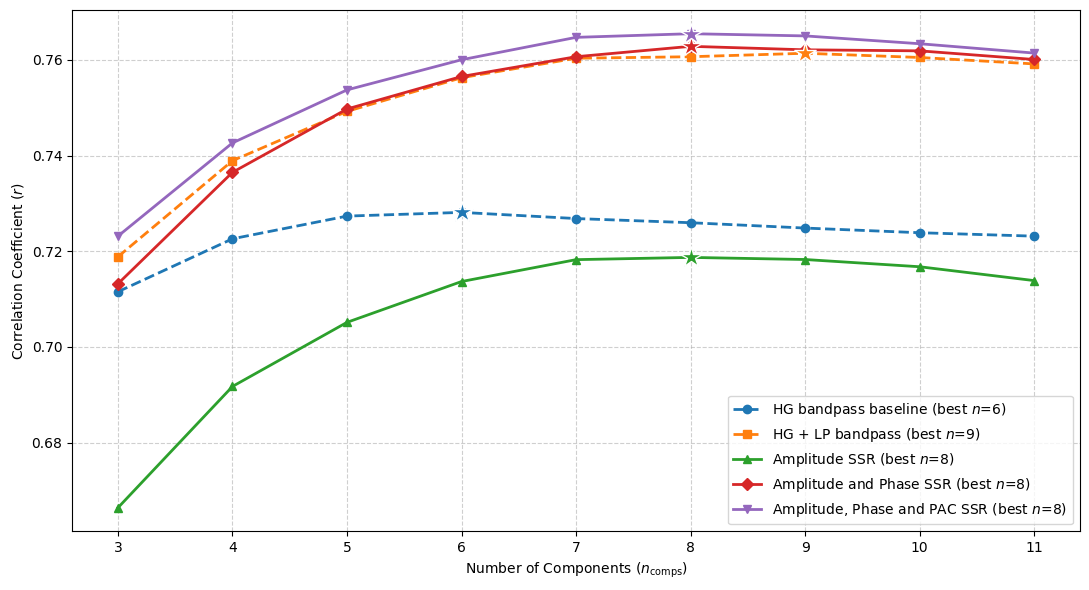

In [13]:
# ---------------------------------------------------------------------
# Plot with optimal components highlighted
# ---------------------------------------------------------------------

markers = ["o", "s", "^", "D", "v"]
linestyles = ["--", "--", "-", "-", "-"]

fig, ax = plt.subplots(figsize=(11, 6))

for i, model_name in enumerate(model_names):
    color = f"C{i}"
    model_scores = scores[i]

    best_index = int(np.nanargmax(model_scores))
    best_n_comp = n_comps_list[best_index]
    best_score = float(model_scores[best_index])
    
    # Complete hyperparameter-search curve
    ax.plot(
        n_comps_list,
        model_scores,
        color=color,
        marker=markers[i],
        linestyle=linestyles[i],
        linewidth=2,
        markersize=6,
        label=(
            f"{model_name} "
            f"(best $n$={best_n_comp})"
        ),
    )

    # Highlight optimum at its exact (n_comp, mean_r) coordinate
    ax.plot(
        best_n_comp,
        best_score,
        marker="*",
        markersize=16,
        color=color,
        markeredgecolor="white",
        markeredgewidth=1,
        linestyle="none",
        zorder=10,
    )

ax.set_xlabel(r"Number of Components ($n_{\mathrm{comps}}$)")
ax.set_ylabel(r"Correlation Coefficient ($r$)")
ax.set_xticks(n_comps_list)

ax.legend(
    #bbox_to_anchor=(1.02, 1),
    loc="lower right",
    frameon=True,
)

ax.grid(True, linestyle="--", alpha=0.6)

fig.tight_layout()
fig.savefig(plot_path, dpi=300, bbox_inches="tight")

plt.savefig(os.path.join(result_path, 'hyperparameter.png'), dpi=600, bbox_inches='tight')
plt.show()
plt.close(fig)

cleanup_memory()

model: HG bandpass baseline, overall mean r: 0.7274
model: HG + LP bandpass, overall mean r: 0.7492
model: Amplitude SSR features, overall mean r: 0.7183
model: Amplitude and phase SSR features, overall mean r: 0.7621
model: Amplitude, phase and PAC SSR features, overall mean r: 0.765


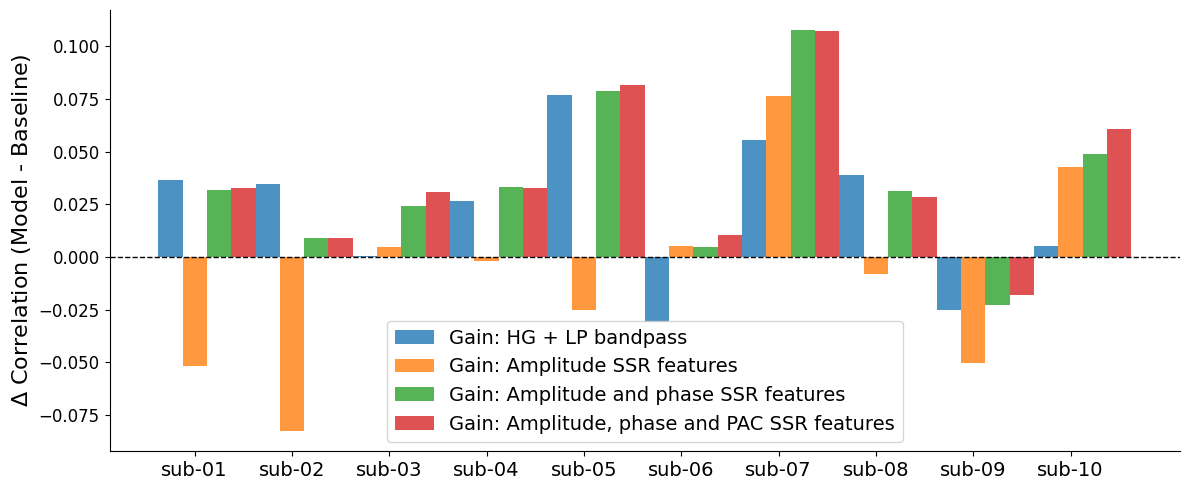

In [15]:
#prefixes = ['_hp_lp_lphase_bandpass', 'only_AMP_sppe_cropped', 'phase_sppe_cropped', 'PAC_sspe_cropped']


prefixes = ['final_bandpass_hg', 'final_bandpass_hg_lp', 'only_AMP_sppe_cropped', 'phase_sppe_cropped', 'PAC_sspe_cropped']#'_hp_lp_bandpass']
names = [
    'HG bandpass baseline', 
    'HG + LP bandpass',
    'Amplitude SSR features', 
    'Amplitude and phase SSR features', 
    'Amplitude, phase and PAC SSR features'
]

title = "Performance Comparison with different Features"


# load and process data
results = []
for i, pre in enumerate(prefixes):
    res = np.load(os.path.join(path_result, f'{pre}linearResults.npy'))
    results.append(res)
    print(f'model: {names[i]}, overall mean r: {round(np.mean(res),4)}')


# calculate mean for each model
subj_means = [np.mean(res, axis=(1, 2)) for res in results]

# calculate delta
delta_b = subj_means[1] - subj_means[0]
delta_c = subj_means[2] - subj_means[0]
delta_d = subj_means[3] - subj_means[0]
delta_e = subj_means[4] - subj_means[0]

deltas = [delta_b, delta_c, delta_d, delta_e]
delta_names = names[1:] # skip the baseline name

x = np.arange(len(subj_means[0]))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))

for i, delta in enumerate(deltas):
    ax.bar(x + (i-1)*width, delta, width, label=f'Gain: {delta_names[i]}', alpha=0.8)

ax.axhline(0, color='black', lw=1, ls='--') # Baseline indicator
ax.set_ylabel('$\Delta$ Correlation (Model - Baseline)', fontsize=16)
#ax.set_title('Performance Improvement Relative to HG Bandpass Baseline', fontsize=16)
ax.set_xticks(x)
ax.tick_params(axis='both', labelsize=12)
ax.set_xticklabels([f'sub-{i+1:02d}' for i in x],fontsize=14)


# Place the legend inside the chart area
ax.legend(loc='best', frameon=True, fontsize=14)


ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(result_path, 'comparison_phase_PAC_amp.png'), dpi=600, bbox_inches='tight')

model: HG bandpass baseline, overall mean r: 0.7281
model: HG + LP bandpass, overall mean r: 0.7614
model: Amplitude SSR features, overall mean r: 0.7187
model: Amplitude and phase SSR features, overall mean r: 0.7628
model: Amplitude, phase and PAC SSR features, overall mean r: 0.7655
(10, 10, 23)


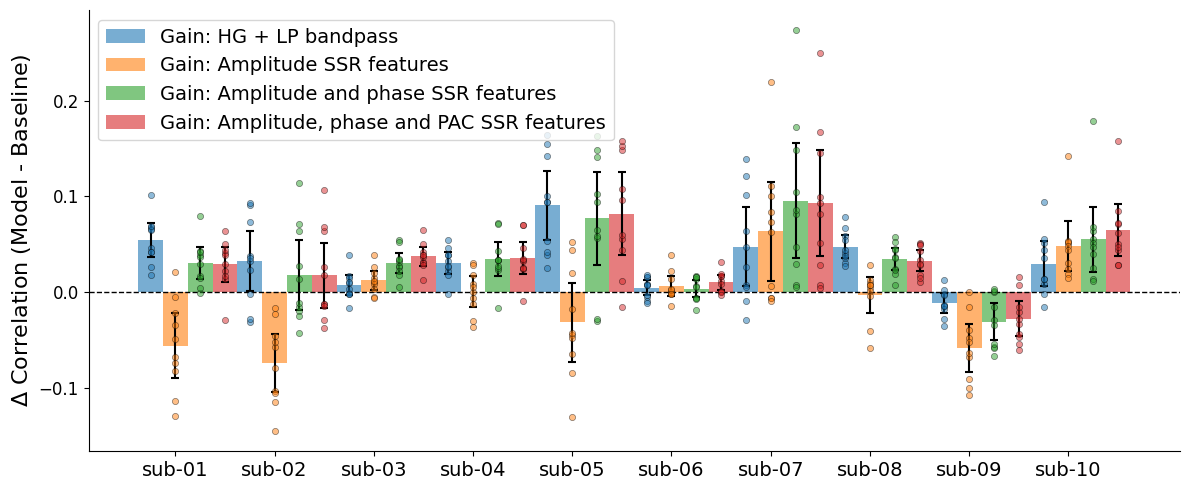

In [15]:
import scipy.stats as stats
prefixes = ['res_final_bandpass_hg', 'res_final_bandpass_hg_lp', 'res_onlyAMP_SSPEfeat', 'res_PHASE_SSPEfeat', 'res_PCA_SSPEfeat']
names = [
    'HG bandpass baseline', 
    'HG + LP bandpass',
    'Amplitude SSR features', 
    'Amplitude and phase SSR features', 
    'Amplitude, phase and PAC SSR features'
]
title = "Performance Comparison with different Features"


# load and process data
results = []
for i, pre in enumerate(prefixes):
    res = np.load(os.path.join(path_result, f'{pre}linearResults.npy'))
    results.append(res)
    print(f'model: {names[i]}, overall mean r: {round(np.mean(res),4)}')


# calculate mean for each model
subj_means = [np.mean(res, axis=(1, 2)) for res in results]

# calculate delta
delta_b = subj_means[1] - subj_means[0]
delta_c = subj_means[2] - subj_means[0]
delta_d = subj_means[3] - subj_means[0]
delta_e = subj_means[4] - subj_means[0]

deltas = [delta_b, delta_c, delta_d, delta_e]
delta_names = names[1:] # skip the baseline name

x = np.arange(len(subj_means[0]))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 5))

print(results[0].shape)

# Calculate the delta for individual folds per subject
fold_means = [np.mean(res, axis=2) for res in results] 

delta_b_folds = fold_means[1] - fold_means[0]  # Shape: (10, 10)
delta_c_folds = fold_means[2] - fold_means[0]  # Shape: (10, 10)
delta_d_folds = fold_means[3] - fold_means[0]  # Shape: (10, 10)
delta_e_folds = fold_means[4] - fold_means[0]

deltas_folds = [delta_b_folds, delta_c_folds, delta_d_folds, delta_e_folds]


x = np.arange(len(results[0])) # X positions for each subject
width = 0.25 # Width of individual bars

# Loop through each model contrast (b, c, d)
for i, delta_folds in enumerate(deltas_folds):
    # Calculate the mean and standard error across the 10 folds (axis=1) for each subject
    sub_means = np.mean(delta_folds, axis=1)
    sub_folds_n = delta_folds.shape[1] # 10 folds
    sub_sems = stats.sem(delta_folds, axis=1)
    
    # Calculate 95% Confidence Interval margin for each subject based on their folds
    ci_margins = sub_sems * stats.t.ppf((1 + 0.95) / 2., sub_folds_n - 1)
    
    # Precise X-position for this specific model's bars across all subjects
    bar_x = x + (i - 1) * width
    
    # A. Plot the main bars
    ax.bar(bar_x, sub_means, width, label=f'Gain: {delta_names[i]}', alpha=0.6, color=f'C{i}')
    
    # B. Add confidence intervals to each bar
    ax.errorbar(bar_x, sub_means, yerr=ci_margins, fmt='none', ecolor='black', 
                capsize=3, elinewidth=1.5, capthick=1.5)
    
    # C. Add individual fold dots for each subject
    for s_idx in range(len(x)):
        subject_fold_data = delta_folds[s_idx, :] # The 10 fold values for this specific subject
        
        
        # Plot the 10 dots (hide from legend to avoid duplicates)
        ax.scatter(np.repeat(bar_x[s_idx], len(subject_fold_data)), 
                   subject_fold_data, color=f'C{i}', edgecolor='black', 
                   s=20, alpha=0.5, zorder=3, linewidths=0.5,
                   label='_nolegend_')

        
ax.axhline(0, color='black', lw=1, ls='--') # Baseline indicator
ax.set_ylabel('$\Delta$ Correlation (Model - Baseline)', fontsize=16)
#ax.set_title('Performance Improvement Relative to HG Bandpass Baseline', fontsize=16)
ax.set_xticks(x)
ax.tick_params(axis='both', labelsize=12)
ax.set_xticklabels([f'sub-{i+1:02d}' for i in x],fontsize=14)


# Place the legend inside the chart area
ax.legend(loc='best', frameon=True, fontsize=14)


ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(result_path, 'correlations_CI_scatter.png'), dpi=600, bbox_inches='tight')

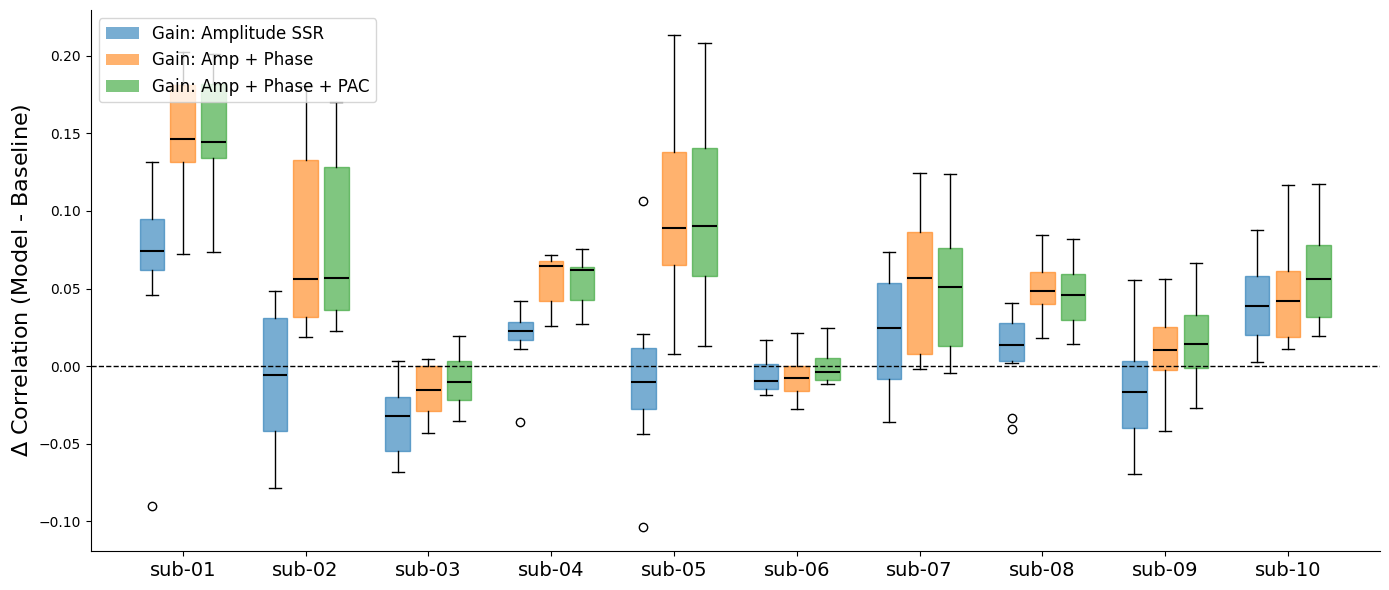

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ... [Your data loading and delta calculation remains the same] ...
# deltas_folds contains 3 arrays of shape (10, 10) -> (subjects, folds)

x = np.arange(10)
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

# Colors matching your original plot
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] 
labels = ['Gain: Amplitude SSR', 'Gain: Amp + Phase', 'Gain: Amp + Phase + PAC']

for i, delta_folds in enumerate(deltas_folds):
    # Positions for this model's boxes across all 10 subjects
    positions = x + (i - 1) * width
    
    # delta_folds.T makes it (folds, subjects) which boxplot expects
    bp = ax.boxplot(delta_folds.T, positions=positions, widths=width*0.8,
                    patch_artist=True, showfliers=True,
                    medianprops=dict(color='black', linewidth=1.5))
    
    # Style the boxes to match your original colors
    for patch in bp['boxes']:
        patch.set_facecolor(colors[i])
        patch.set_alpha(0.6)
        patch.set_edgecolor(colors[i])

# Create a custom legend manually since boxplots don't automatically label nicely
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors[i], alpha=0.6, label=labels[i]) for i in range(3)]
ax.legend(handles=legend_elements, loc='upper left', frameon=True, fontsize=12)

# Formatting
ax.axhline(0, color='black', lw=1, ls='--')
ax.set_ylabel('$\Delta$ Correlation (Model - Baseline)', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels([f'sub-{i+1:02d}' for i in x], fontsize=14)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(result_path, 'comparison_boxplot.png'), dpi=600, bbox_inches='tight')

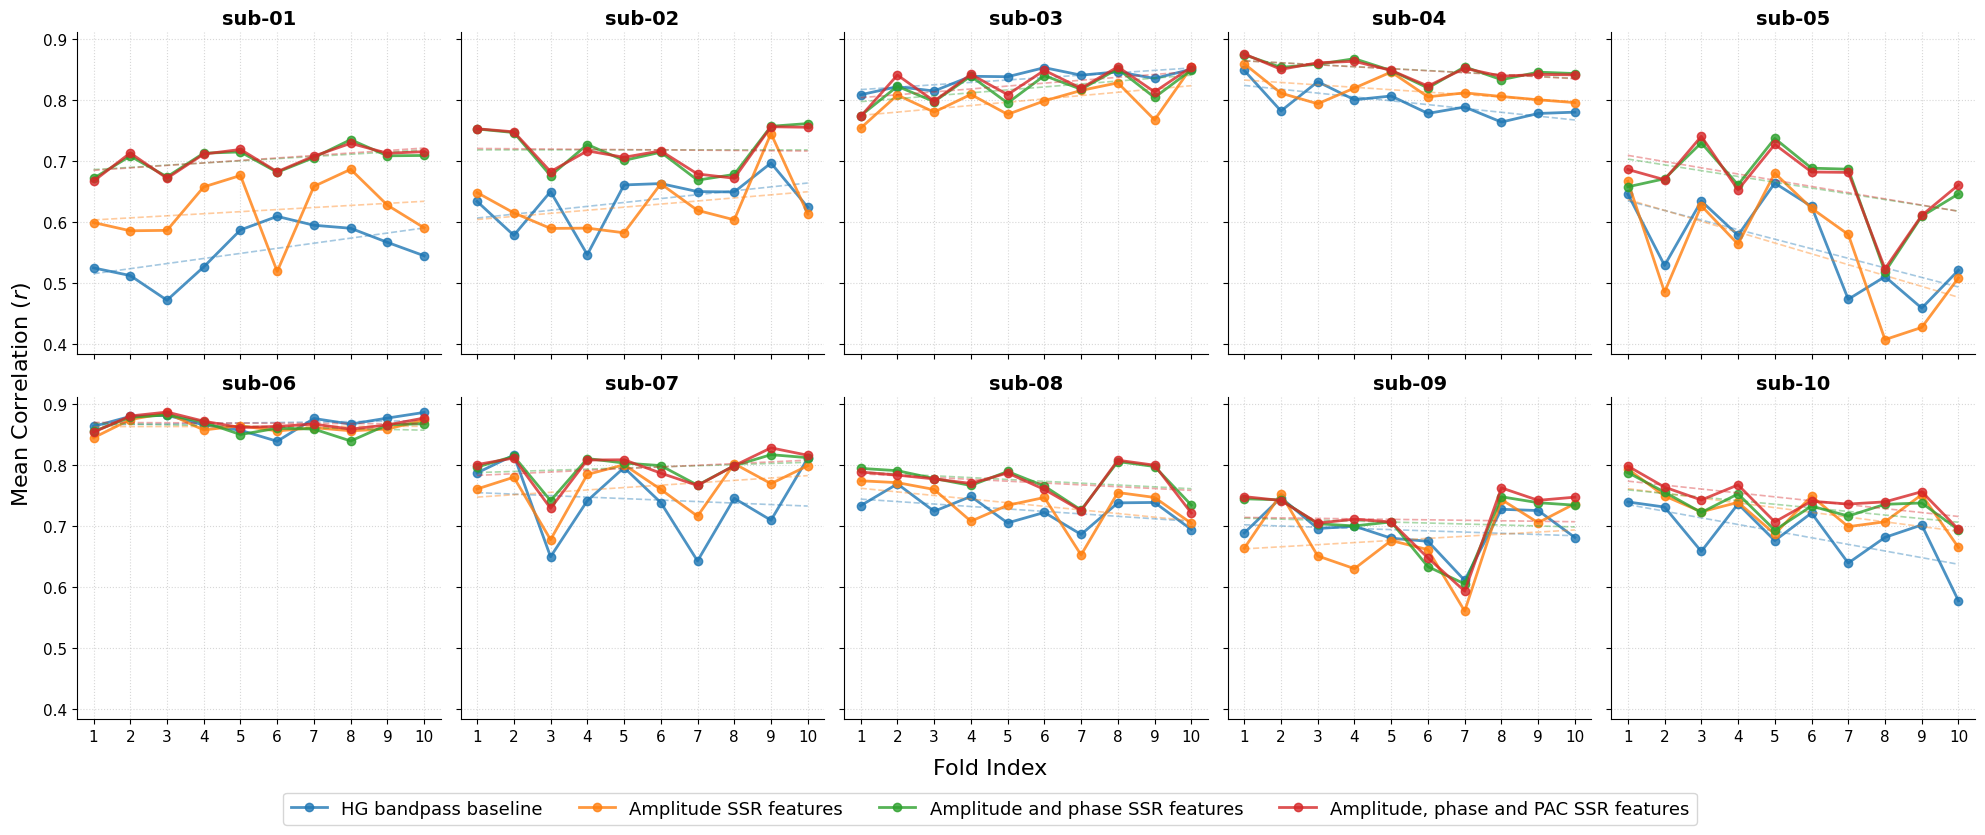

--- Per-Subject Stability Metrics ---

[Subject 01]
  HG bandpass baseline Slope: 0.00835
  Amplitude SSR features Slope: 0.00340
  Amplitude and phase SSR features Slope: 0.00359
  Amplitude, phase and PAC SSR features Slope: 0.00408

[Subject 02]
  HG bandpass baseline Slope: 0.00639
  Amplitude SSR features Slope: 0.00507
  Amplitude and phase SSR features Slope: -0.00000
  Amplitude, phase and PAC SSR features Slope: -0.00047

[Subject 03]
  HG bandpass baseline Slope: 0.00394
  Amplitude SSR features Slope: 0.00542
  Amplitude and phase SSR features Slope: 0.00482
  Amplitude, phase and PAC SSR features Slope: 0.00476

[Subject 04]
  HG bandpass baseline Slope: -0.00631
  Amplitude SSR features Slope: -0.00397
  Amplitude and phase SSR features Slope: -0.00320
  Amplitude, phase and PAC SSR features Slope: -0.00326

[Subject 05]
  HG bandpass baseline Slope: -0.01570
  Amplitude SSR features Slope: -0.01782
  Amplitude and phase SSR features Slope: -0.00949
  Amplitude, phase and 

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import os

n_subjects = results[0].shape[0]  # 10 subjects
n_folds = results[0].shape[1]     # 10 folds
folds = np.arange(1, n_folds + 1)

# Create a 2x5 grid of subplots for the 10 subjects
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()  # Flatten into a 1D array of 10 axes for easy looping

# Standard colors matching your style
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] 

# Loop through each subject
for s_idx in range(n_subjects):
    ax = axes[s_idx]
    
    # Loop through each model feature type
    for i, res in enumerate(results):
        # Average over Mel-bins (axis 2) -> shape: (n_subjects, n_folds)
        sub_fold_matrix = np.mean(res, axis=2)
        
        # Pull out the exact 10-fold trajectory for this specific subject
        subject_trajectory = sub_fold_matrix[s_idx, :]
        
        # Plot the trajectory line for this subject
        ax.plot(folds, subject_trajectory, marker='o', linewidth=2, 
                color=colors[i], alpha=0.8, label=names[i] if s_idx == 0 else "_nolegend_")
        
        # Fit and plot the linear trendline (Dotted Line)
        slope, intercept = np.polyfit(folds, subject_trajectory, 1)
        ax.plot(folds, slope * folds + intercept, linestyle='--', 
                color=colors[i], alpha=0.4, linewidth=1.2)
        
    # Individual subplot styling
    ax.set_title(f'sub-{s_idx+1:02d}', fontsize=14, fontweight='bold')
    ax.set_xticks(folds)
    ax.grid(axis='both', linestyle=':', alpha=0.5)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', labelsize=11)

# Add shared labels across the outer perimeter of the grid
fig.supxlabel('Fold Index', fontsize=16, y=0.02)
fig.supylabel('Mean Correlation ($r$)', fontsize=16, x=0.01)

# Place one global legend at the top or bottom to keep the subplots clean
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05),
           ncol=4, fontsize=13, frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(result_path, 'fold_stability_trends_per_subject.png'), 
            dpi=600, bbox_inches='tight')
plt.show()

# --- Subject-Specific Metrics Calculations ---
print("--- Per-Subject Stability Metrics ---")
for s_idx in range(n_subjects):
    print(f"\n[Subject {s_idx+1:02d}]")
    for i, res in enumerate(results):
        sub_fold_matrix = np.mean(res, axis=2)
        subject_trajectory = sub_fold_matrix[s_idx, :]
        slope, _ = np.polyfit(folds, subject_trajectory, 1)
        print(f"  {names[i]} Slope: {slope:.5f}")

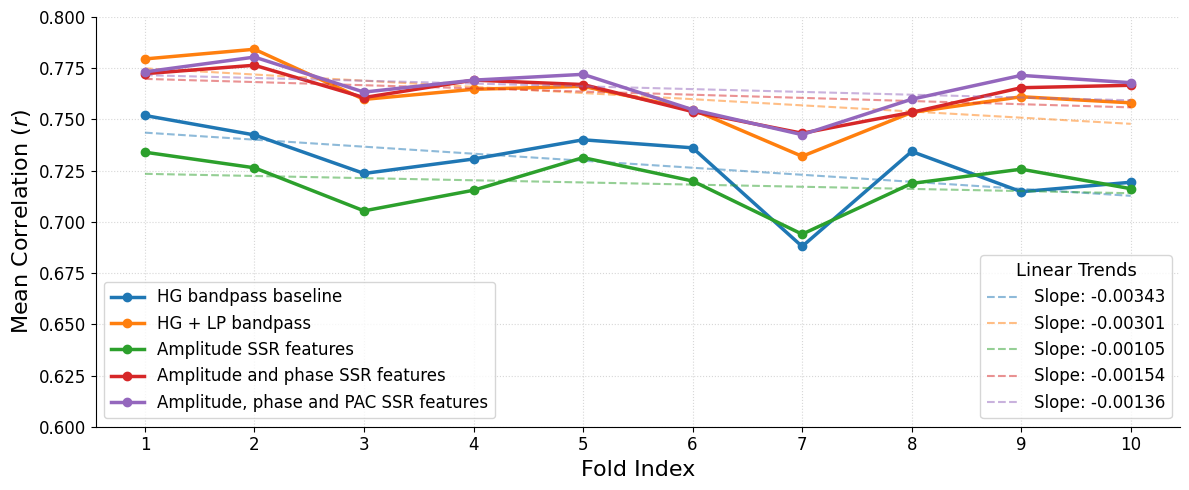

--- Stability Metrics ---
Gains over baseline across all 10 folds: [0.0204 0.034  0.0371 0.0385 0.027  0.0177 0.0553 0.0191 0.0508 0.0473]
Min gain: 0.0177 (Fold 6)
Max gain: 0.0553 (Fold 7)
Mean gain across folds: 0.0347 ± 0.0129
Full model trajectory slope per fold:
pac: -0.00154
phase: -0.00105
amp: -0.00301
baseline: -0.00343


In [16]:
#fold stability plot


n_folds = results[0].shape[1]
folds = np.arange(1, n_folds + 1)

fig, ax = plt.subplots(figsize=(12, 5))

trend_handles = []
trend_labels = []

for i, res in enumerate(results):
    # Average over observations (axis 2) -> shape: (n_subjects, n_folds)
    sub_fold_matrix = np.mean(res, axis=2)
    
    
    # Calculate grand mean and SEM across subjects for each fold
    grand_mean_per_fold = np.mean(sub_fold_matrix, axis=0)
    sem_per_fold = np.std(sub_fold_matrix, axis=0) / np.sqrt(sub_fold_matrix.shape[0])
    
    # Plot the group-level trajectory
    ax.plot(folds, grand_mean_per_fold, marker='o', linewidth=2.5, 
            label=names[i], color=f'C{i}')
    #ax.fill_between(folds, grand_mean_per_fold - sem_per_fold, grand_mean_per_fold + sem_per_fold, color=f'C{i}', alpha=0.15)
    # Step 4: Fit and plot the linear trendline (Dotted Line)
    slope, intercept = np.polyfit(folds, grand_mean_per_fold, 1)
    trend, = ax.plot(folds, slope * folds + intercept, linestyle='--', 
                     color=f'C{i}', alpha=0.5, linewidth=1.5)
    
    # Keep track of trendline data for the second legend
    trend_handles.append(trend)
    trend_labels.append(f'Slope: {slope:.5f}')

# Styling
ax.set_xlabel('Fold Index', fontsize=16)
ax.set_ylabel('Mean Correlation ($r$)', fontsize=16)
#ax.set_title('Model Performance Stability Across Folds', fontsize=16, pad=15)
ax.set_xticks(folds)
ax.set_ylim(0.6, 0.80) 
ax.grid(axis='both', linestyle=':', alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)


#ax.legend(fontsize=11, loc='lower left')
# Legend 1: Main models (Bottom Left)
leg1 = ax.legend(fontsize=12, loc='lower left')

# Legend 2: Trendlines & Slopes (Bottom Right)
# We must manually add the first legend back as an artist, otherwise it gets overwritten
ax.add_artist(leg1)
ax.legend(trend_handles, trend_labels, fontsize=12, loc='lower right', 
          title="Linear Trends", title_fontsize=13)

ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.savefig(os.path.join(result_path, 'fold_stability_trends.png'), dpi=600)
plt.show()


# Compute the subject-fold matrices for each model (shape: n_subjects, n_folds)
baseline_sf = np.mean(results[0], axis=2)
amp_sf = np.mean(results[1], axis=2)
phase_sf = np.mean(results[2], axis=2)
pac_sf = np.mean(results[3], axis=2)

# Get group means per fold
mean_baseline = np.mean(baseline_sf, axis=0)
mean_pac = np.mean(pac_sf, axis=0)
mean_phase = np.mean(phase_sf, axis=0)
mean_amp = np.mean(amp_sf, axis=0)

# Calculate the improvement over baseline for every single fold
gains_per_fold = mean_pac - mean_baseline

print("--- Stability Metrics ---")
print(f"Gains over baseline across all 10 folds: {np.round(gains_per_fold, 4)}")
print(f"Min gain: {round(np.min(gains_per_fold), 4)} (Fold {np.argmin(gains_per_fold)+1})")
print(f"Max gain: {round(np.max(gains_per_fold), 4)} (Fold {np.argmax(gains_per_fold)+1})")
print(f"Mean gain across folds: {round(np.mean(gains_per_fold), 4)} ± {round(np.std(gains_per_fold), 4)}")

# Check for a downward trend in the full model using a simple linear fit slope
slopepac, _ = np.polyfit(folds, mean_pac, 1)
slopephase, _ = np.polyfit(folds, mean_phase, 1)
slopeamp, _ = np.polyfit(folds, mean_amp, 1)
slopebase, _ = np.polyfit(folds, mean_baseline, 1)

print("Full model trajectory slope per fold:")
print(f"pac: {round(slopepac, 5)}")
print(f"phase: {round(slopephase, 5)}")
print(f"amp: {round(slopeamp, 5)}")
print(f"baseline: {round(slopebase, 5)}")



In [19]:
#summary results table


# Define prefixes and paths
prefixes = ["res_final_bandpass_hg", "res_final_bandpass_hg_lp", "res_onlyAMP_SSPEfeat", "res_PHASE_SSPEfeat", "res_PCA_SSPEfeat"]
# Mapping prefixes to meaningful names for your report
model_names = {
    "res_final_bandpass_hg": "HG Bandpass (Baseline)",
    "res_final_bandpass_hg_lp": "HG + LP",
    "res_onlyAMP_SSPEfeat": "Amplitude Only SSPE",
    "res_PHASE_SSPEfeat": "Amp + Phase SSPE",
    "res_PCA_SSPEfeat": "Amp + Phase + PAC SSPE"
}

result_path = '/Users/lisa/Documents/DSAI_year2/SingleWordProductionDutch-1/results'

print(f"{'Model Framework':<35} | {'Mean r':<8} | {'Random Control (mean ± sd)':<28} | {'Group Z-score':<12}")
print("-" * 93)

# Loop through each model type
for prefix in prefixes:
    # Load the specific results for this framework
    allRes = np.load(os.path.join(result_path, f'{prefix}linearResults.npy'))
    randomControl = np.load(os.path.join(result_path, f'{prefix}randomResults.npy'))
    
    # Track metrics across all 10 participants
    sub_model_means = []
    sub_rand_means = []
    sub_rand_stds = []
    
    for p in range(10):
        # Calculate participant-specific means
        sub_model_means.append(allRes[p].mean())
        sub_rand_means.append(randomControl[p].mean())
        sub_rand_stds.append(randomControl[p].std())
        
    # Calculate Group-Level Grand Means
    group_model_mean = np.mean(sub_model_means)
    group_rand_mean = np.mean(sub_rand_means)
    group_rand_std = np.mean(sub_rand_stds) # Average standard deviation of the chance distribution
    
    # Group Z-score: how many standard deviations the group mean is from the group chance mean
    group_z = (group_model_mean - group_rand_mean) / group_rand_std
    
    # Print row
    name = model_names.get(prefix, prefix)
    rand_str = f"{group_rand_mean:.4f} ± {group_rand_std:.4f}"
    print(f"{name:<35} | {group_model_mean:.4f}  | {rand_str:<28} | {group_z:.2f}")

Model Framework                     | Mean r   | Random Control (mean ± sd)   | Group Z-score
---------------------------------------------------------------------------------------------
HG Bandpass (Baseline)              | 0.7281  | 0.0017 ± 0.1601              | 4.54
HG + LP                             | 0.7614  | -0.0011 ± 0.1599             | 4.77
Amplitude Only SSPE                 | 0.7187  | 0.0016 ± 0.1601              | 4.48
Amp + Phase SSPE                    | 0.7628  | 0.0003 ± 0.1601              | 4.76
Amp + Phase + PAC SSPE              | 0.7655  | -0.0001 ± 0.1601             | 4.78


In [20]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

# Assumed order:
# subj_means[0] = HG bandpass
# subj_means[1] = HG + LP bandpass
# subj_means[2] = Amplitude-only SSR
# subj_means[3] = Amplitude + phase SSR
# subj_means[4] = Amplitude + phase + PAC SSR

# ---------------------------------------------------------
# QUESTION 1: Conventional bandpass models
# ---------------------------------------------------------
t_lp, p_lp = ttest_rel(subj_means[1], subj_means[0])

# ---------------------------------------------------------
# QUESTION 2: Matched framework comparisons
# ---------------------------------------------------------
t_amp_framework, p_amp_framework = ttest_rel(
    subj_means[2], subj_means[0]
)  # SSR amplitude vs HG

t_phase_framework, p_phase_framework = ttest_rel(
    subj_means[3], subj_means[1]
)  # SSR amp+phase vs HG+LP

t_full_framework, p_full_framework = ttest_rel(
    subj_means[4], subj_means[1]
)  # Full SSR vs HG+LP

# Holm correction across the 3 framework comparisons
reject_framework, p_corr_framework, _, _ = multipletests(
    [p_amp_framework, p_phase_framework, p_full_framework],
    alpha=0.05,
    method="holm"
)

# ---------------------------------------------------------
# QUESTION 3: Incremental value within SSR
# ---------------------------------------------------------
t_phase, p_phase = ttest_rel(
    subj_means[3], subj_means[2]
)  # add phase

t_pac, p_pac = ttest_rel(
    subj_means[4], subj_means[3]
)  # add PAC

reject_steps, p_corr_steps, _, _ = multipletests(
    [p_phase, p_pac],
    alpha=0.05,
    method="holm"
)

print("============================================================")
print("QUESTION 1: Does adding low-frequency bandpass features help?")
print("============================================================")
print(f"HG+LP vs HG:")
print(f"  t = {t_lp:+.4f}")
print(f"  p = {p_lp:.5f}")

print("\n============================================================")
print("QUESTION 2: SSR vs matched conventional representations")
print("============================================================")

labels = [
    "SSR amplitude vs HG",
    "SSR amplitude+phase vs HG+LP",
    "Full SSR vs HG+LP",
]

ts = [t_amp_framework, t_phase_framework, t_full_framework]
ps = [p_amp_framework, p_phase_framework, p_full_framework]

for label, t, p_raw, p_corr, reject in zip(
    labels, ts, ps, p_corr_framework, reject_framework
):
    print(label)
    print(f"  t             = {t:+.4f}")
    print(f"  raw p         = {p_raw:.5f}")
    print(f"  Holm-corrected p = {p_corr:.5f}")
    print(f"  significant   = {reject}")
    print("-" * 50)

print("\n============================================================")
print("QUESTION 3: Incremental value within SSR")
print("============================================================")

print("Adding phase: Amp+Phase vs Amp")
print(f"  t             = {t_phase:+.4f}")
print(f"  raw p         = {p_phase:.5f}")
print(f"  Holm-corrected p = {p_corr_steps[0]:.5f}")

print("\nAdding PAC: Full SSR vs Amp+Phase")
print(f"  t             = {t_pac:+.4f}")
print(f"  raw p         = {p_pac:.5f}")
print(f"  Holm-corrected p = {p_corr_steps[1]:.5f}")

QUESTION 1: Does adding low-frequency bandpass features help?
HG+LP vs HG:
  t = +3.5952
  p = 0.00579

QUESTION 2: SSR vs matched conventional representations
SSR amplitude vs HG
  t             = -0.6517
  raw p         = 0.53088
  Holm-corrected p = 1.00000
  significant   = False
--------------------------------------------------
SSR amplitude+phase vs HG+LP
  t             = +0.1936
  raw p         = 0.85081
  Holm-corrected p = 1.00000
  significant   = False
--------------------------------------------------
Full SSR vs HG+LP
  t             = +0.5222
  raw p         = 0.61413
  Holm-corrected p = 1.00000
  significant   = False
--------------------------------------------------

QUESTION 3: Incremental value within SSR
Adding phase: Amp+Phase vs Amp
  t             = +3.6676
  raw p         = 0.00517
  Holm-corrected p = 0.01035

Adding PAC: Full SSR vs Amp+Phase
  t             = +1.9714
  raw p         = 0.08016
  Holm-corrected p = 0.08016


In [24]:
import numpy as np

# subj_means[3] = Amplitude + phase SSR
# subj_means[4] = Amplitude + phase + PAC SSR

n_improved_pac = np.sum(np.asarray(subj_means[4]) > np.asarray(subj_means[1]))
n_total = len(subj_means[3])

print(f"Performance increased in {n_improved_pac} of {n_total} participants.")

Performance increased in 5 of 10 participants.


In [25]:
n_improved_phase = np.sum(np.asarray(subj_means[3]) > np.asarray(subj_means[1]))
print(f"Adding phase improved performance in {n_improved_phase} of {n_total} participants.")

Adding phase improved performance in 4 of 10 participants.
